# RMSIN: Rotated Multi-Scale Interaction Network for RRSIS
## Referring Remote Sensing Image Segmentation on RRSIS-D

**Text Encoder**: HuggingFace `bert-base-uncased`  
**Vision Backbone**: MultiModalSwinTransformer (Swin-Base, ImageNet-22K pretrained via `timm`)  
**Fusion**: PWAM (Pixel-Word Attention Module) — ***will be replaced with GNN***  
**Decoder**: SimpleDecoding with Adaptive Rotated Convolutions  
**Loss**: CE + Dice  

---

### Notebook Sections
| # | Section | Content |
|---|---------|--------|
| 1 | Setup | Installs, paths, imports, RMSIN repo verification |
| 2 | Config | All hyperparameters in one `Config` class |
| 3 | Visualization | Explore RRSIS-D images, masks, referring text |
| 4 | Dataset & Transforms | `RRSISDDataset` with HF tokenizer |
| 5 | Backbone | Full `MultiModalSwinTransformer` + PWAM (**GNN replacement target**) |
| 6 | Decoder | `SimpleDecoding` with ARC |
| 7 | Model Assembly | `RMSINModel` tying everything together |
| 8 | Loss | Combined CE + Dice |
| 9 | Metrices | Evaluation metrices |
| 10 | Logging | Tracking, checkpointing, logging |
| 11 | Training | Optimizer, train/eval loops |
| 12 | Testing | Testing infrastructure |
| 13 | GNN Variants | Standalone modules for future fusion experiments |

### Repo-as-Package Strategy
The RMSIN repo is uploaded as a Kaggle Dataset. We import **only** these unchanged modules:  
`arc` (AdaptiveRotatedConv2d) • `lib.cross_scale_interaction` (CIM) • `lib.various_receptive` (VariousReceptive)  

Everything else is in this notebook for easy modification.



---
## 1. Setup & Installation


In [1]:
!pip install -q einops torchinfo tabulate

In [2]:
# ============================================================
# 1a. Environment detection & path setup
# ============================================================
import sys, os

IS_KAGGLE = os.path.exists('/kaggle')
IS_COLAB  = 'google.colab' in sys.modules or os.path.exists('/content')

# if IS_KAGGLE:
#     RMSIN_REPO_PATH = '/kaggle/input/datasets/fahims45/rmsin-source/rmsin_src'
#     DATASET_ROOT    = '/kaggle/input/datasets/fahims45/rrsis-d/RRSIS-D'
#     OUTPUT_DIR      = '/kaggle/working'

if IS_COLAB:
    # ── mount Google Drive ───────────────────────────────────
    from google.colab import drive
    drive.mount('/content/drive', force_remount=False)

    RMSIN_REPO_PATH = '/content/drive/MyDrive/RRSIS-D_CSE465/Notebooks/rmsin_src'          # uploaded via Colab Files panel
    DATASET_ROOT    = '/content/drive/MyDrive/RRSIS-D_CSE465/Datasets/RRSIS-D'             # uploaded via Colab Files panel
    OUTPUT_DIR      = '/content/drive/MyDrive/RRSIS-D_CSE465/Checkpoints'   # persistent on Drive

else:
    RMSIN_REPO_PATH = './RMSIN/rmsin_src'
    DATASET_ROOT    = './RRSIS-D'
    OUTPUT_DIR      = './checkpoints'

if RMSIN_REPO_PATH not in sys.path:
    sys.path.insert(0, RMSIN_REPO_PATH)

os.makedirs(OUTPUT_DIR, exist_ok=True)


ENV = 'Kaggle' if IS_KAGGLE else ('Colab' if IS_COLAB else 'Local')
print(f'Environment : {ENV}')
print(f'Repo        : {RMSIN_REPO_PATH}')
print(f'Dataset     : {DATASET_ROOT}')
print(f'Output      : {OUTPUT_DIR}')

Mounted at /content/drive
Environment : Kaggle
Repo        : /content/drive/MyDrive/RRSIS-D_CSE465/Notebooks/rmsin_src
Dataset     : /content/drive/MyDrive/RRSIS-D_CSE465/Datasets/RRSIS-D
Output      : /content/drive/MyDrive/RRSIS-D_CSE465/Checkpoints


In [3]:
# ─────────────────────────────────────────────────────────────
# 1b — Core Imports
# ─────────────────────────────────────────────────────────────

import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.utils.checkpoint as checkpoint_util
from torch.utils.data import Dataset, DataLoader
from collections import defaultdict, OrderedDict
from typing import Optional
from torch import Tensor

import matplotlib.pyplot as plt
from tabulate import tabulate
from torchinfo import summary

import numpy as np
import random
import json
import pickle
import time
import datetime
import gc
import math
import warnings
from pathlib import Path

import cv2
from PIL import Image
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from pycocotools import mask as maskUtils
import subprocess, shutil, json
%matplotlib inline

from transformers import ConvNextV2Model, ConvNextV2Config
from transformers import BertModel, BertTokenizer
import timm
from timm.layers import DropPath, to_2tuple, trunc_normal_
from tqdm.notebook import tqdm

torch.backends.cuda.matmul.allow_tf32 = True
torch.backends.cudnn.allow_tf32 = True

warnings.filterwarnings('ignore')

DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Device: {DEVICE}')
if torch.cuda.is_available():
    print(f'GPU: {torch.cuda.get_device_name(0)}')
    print(f'VRAM: {torch.cuda.get_device_properties(0).total_memory / 1024**3:.1f} GB')

Device: cuda
GPU: NVIDIA A100-SXM4-40GB
VRAM: 39.5 GB


In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [4]:
# ============================================================
# 1c. Reproductibility
# ============================================================

def seed_everything(seed=2401):
    random.seed(seed)
    os.environ['PYTHONHASHSEED'] = str(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.benchmark = True       # ← fixed input 480x480, safe to enable
    torch.backends.cudnn.deterministic = False   # ← trade exact reproducibility for speed

seed_everything(2401)

In [5]:
# ============================================================
# 1d. Verify RMSIN repo imports
# ============================================================

repo_ok = True

try:
    from arc import AdaptiveRotatedConv2d, RountingFunction
    print('[OK] arc (AdaptiveRotatedConv2d, RountingFunction)')
except ImportError as e:
    print(f'[FAIL] arc: {e}')
    print('  Fix: ensure arc/__init__.py exports these classes')
    repo_ok = False

try:
    from lib.cross_scale_interaction import CIM
    print('[OK] CIM (Cross-scale Interaction Module)')
except ImportError as e:
    print(f'[FAIL] CIM: {e}')
    repo_ok = False

try:
    from lib.various_receptive import VariousReceptive
    print('[OK] VariousReceptive')
except ImportError as e:
    print(f'[FAIL] VariousReceptive: {e}')
    repo_ok = False

if not repo_ok:
    print('\n*** Some repo imports failed. Check paths and __init__.py files. ***')
else:
    print('\nAll repo imports successful!')


[OK] arc (AdaptiveRotatedConv2d, RountingFunction)
[OK] CIM (Cross-scale Interaction Module)
[OK] VariousReceptive

All repo imports successful!


---
## 2. Configuration


In [6]:
class Config:
    """Central config — replaces args.py."""
    # Paths
    dataset_root = DATASET_ROOT
    output_dir   = OUTPUT_DIR
    resume       = ''

    # Dataset
    dataset  = 'rrsisd'
    splitBy  = 'unc'
    img_size = 480

    # Model
    swin_type   = 'base'
    window12    = True
    mha         = ''
    fusion_drop = 0.0
    bert_type   = 'bert-base-uncased'

    # Backbone selection for ablation
    backbone         = 'convnextv2'                         # 'swin' or 'convnextv2'
    convnextv2_model = 'facebook/convnextv2-base-22k-224'   # HF model ID

    # Mixed precision
    use_bf16 = True   # A100 native bf16; set False for fp32 baseline comparison

    # Training
    epochs       = 40
    batch_size   = 32
    lr           = 3e-5
    weight_decay = 1e-2
    amsgrad      = False
    loss_weight  = 0.1
    max_tokens   = 20

    # DataLoader
    num_workers = 4
    pin_memory  = True

    # Logging
    print_freq = 10
    model_id   = 'RMSIN_RRSISD'

    # Derived (used when backbone='swin')
    @property
    def embed_dim(self):
        return {'tiny': 96, 'small': 96, 'base': 128, 'large': 192}[self.swin_type]
    @property
    def depths(self):
        return {'tiny': [2,2,6,2], 'small': [2,2,18,2],
                'base': [2,2,18,2], 'large': [2,2,18,2]}[self.swin_type]
    @property
    def num_heads_swin(self):
        return {'tiny': [3,6,12,24], 'small': [3,6,12,24],
                'base': [4,8,16,32], 'large': [6,12,24,48]}[self.swin_type]
    @property
    def window_size(self):
        return 12 if self.window12 else 7
    @property
    def mha_list(self):
        return [int(x) for x in self.mha.split('-')] if self.mha else [1,1,1,1]

cfg = Config()
print(f'Backbone: {cfg.backbone}')
if cfg.backbone == 'convnextv2':
    print(f'ConvNeXt-V2 model: {cfg.convnextv2_model}')
else:
    print(f'Swin: {cfg.swin_type} | embed_dim={cfg.embed_dim} | window={cfg.window_size}')
print(f'Training: epochs={cfg.epochs} | bs={cfg.batch_size} | lr={cfg.lr}')
print(f'max_tokens={cfg.max_tokens}')
print(f'output_dir: {cfg.output_dir}')

Backbone: convnextv2
ConvNeXt-V2 model: facebook/convnextv2-base-22k-224
Training: epochs=40 | bs=32 | lr=3e-05
max_tokens=20
output_dir: /content/drive/MyDrive/RRSIS-D_CSE465/Checkpoints


---
## 3. Data Exploration & Visualization


In [7]:
# ============================================================
# 3a. Load RRSIS-D metadata
# ============================================================

instances_path = os.path.join(cfg.dataset_root, 'instances.json')
with open(instances_path, 'r') as f:
    instances = json.load(f)

print(f'Images:      {len(instances["images"])}')
print(f'Annotations: {len(instances["annotations"])}')
print(f'Categories:  {len(instances["categories"])}')

# Load referring expressions
refs_path = os.path.join(cfg.dataset_root, f'refs({cfg.splitBy}).p')
with open(refs_path, 'rb') as f:
    all_refs = pickle.load(f)

print(f'Referring expressions: {len(all_refs)}')

split_counts = defaultdict(int)
for ref in all_refs:
    split_counts[ref['split']] += 1
print('Splits:', dict(sorted(split_counts.items())))


Images:      17402
Annotations: 17402
Categories:  20
Referring expressions: 17402
Splits: {'test': 3481, 'train': 12181, 'val': 1740}


In [8]:
# ============================================================
# 3b. Mask decoding utility
# ============================================================

img_dict = {img['id']: img for img in instances['images']}
ann_dict = {ann['id']: ann for ann in instances['annotations']}

def decode_mask(ann, img_info):
    """Decode COCO-format segmentation into binary mask."""
    seg = ann['segmentation']
    h, w = img_info['height'], img_info['width']

    def _safe_decode(rle, h, w):
        """Decode RLE and force to (h, w) if annotation size mismatches."""
        m = maskUtils.decode(rle)
        if m.shape[:2] != (h, w):
            m = cv2.resize(m, (w, h), interpolation=cv2.INTER_NEAREST)
        return m

    if isinstance(seg, dict):
        if isinstance(seg['counts'], list):
            rle = maskUtils.frPyObjects(seg, h, w)
        else:
            rle = seg
        m = _safe_decode(rle, h, w)

    elif isinstance(seg, list):
        if len(seg) > 0 and isinstance(seg[0], dict):
            # List of RLE dicts — decode each and accumulate
            m = np.zeros((h, w), dtype=np.uint8)
            for s in seg:
                m += _safe_decode(s, h, w)          # ← was the crash point
            m = (m > 0).astype(np.uint8)

        elif len(seg) > 0 and isinstance(seg[0], str):
            rle = {'counts': seg[0], 'size': [h, w]}
            m = _safe_decode(rle, h, w)

        else:
            # Polygon format
            rle = maskUtils.frPyObjects(seg, h, w)
            m = maskUtils.decode(rle)
            if m.ndim == 3:
                m = m.sum(axis=2)
            m = (m > 0).astype(np.uint8)
    else:
        m = np.zeros((h, w), dtype=np.uint8)

    if m.ndim == 3:
        m = m.sum(axis=2)
    return (m > 0).astype(np.uint8)

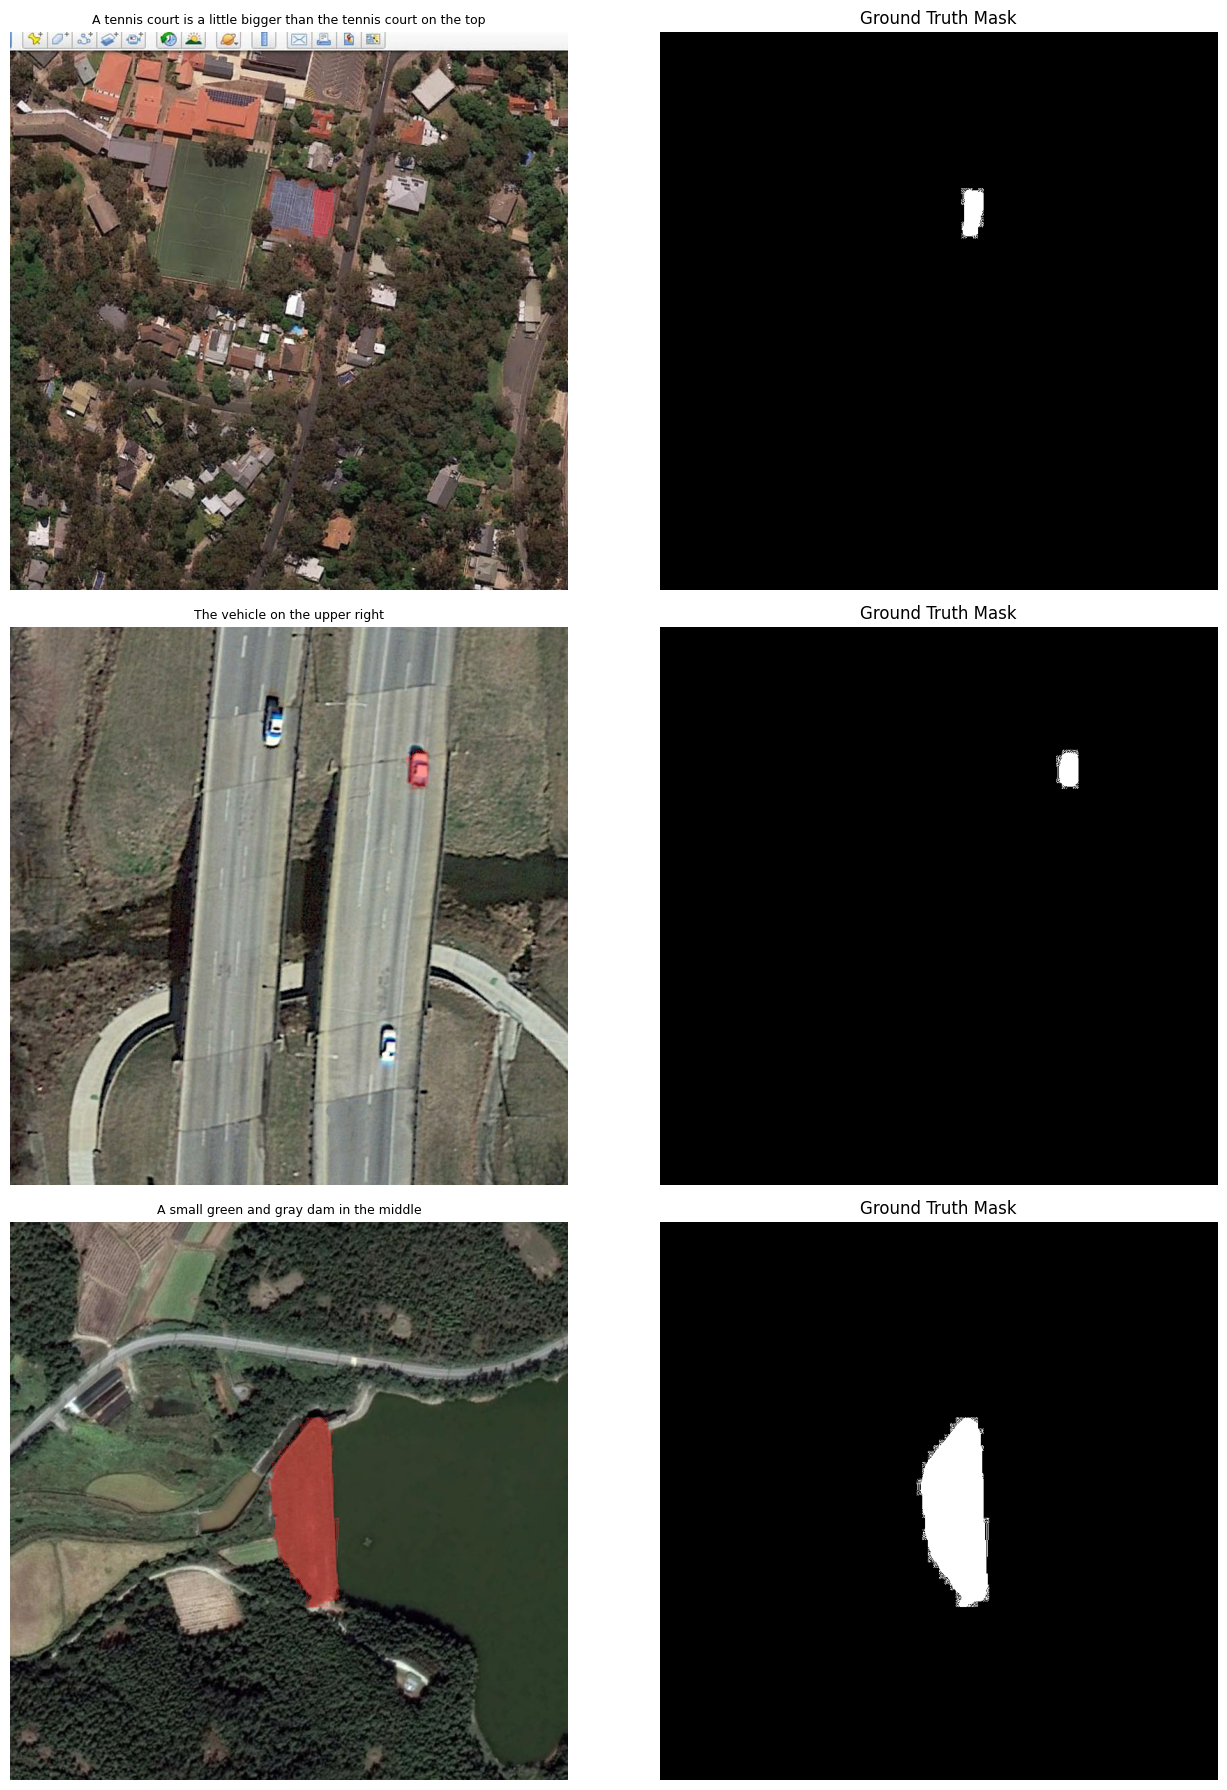

In [10]:
# ============================================================
# 3c. Visualize samples
# ============================================================

img_dir = os.path.join(cfg.dataset_root, 'JPEGImages')

sample_refs = random.sample(all_refs, min(6, len(all_refs)))
fig, axes = plt.subplots(3, 2, figsize=(14, 18))

for i, ref in enumerate(sample_refs[:3]):
    img_info = img_dict[ref['image_id']]
    ann = ann_dict[ref['ann_id']]
    img = cv2.imread(os.path.join(img_dir, img_info['file_name']))
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    mask_arr = decode_mask(ann, img_info)

    # Image + overlay
    overlay = img.copy()
    overlay[mask_arr > 0] = (overlay[mask_arr > 0] * 0.5 +
                             np.array([255, 50, 50]) * 0.5).astype(np.uint8)
    sents = [s['sent'] for s in ref['sentences']]
    axes[i, 0].imshow(overlay)
    axes[i, 0].set_title('\n'.join(sents[:2]), fontsize=9, wrap=True)
    axes[i, 0].axis('off')

    # Mask
    axes[i, 1].imshow(mask_arr, cmap='gray')
    axes[i, 1].set_title('Ground Truth Mask')
    axes[i, 1].axis('off')

plt.tight_layout()
plt.show()


---
## 4. Dataset & Transforms


In [9]:
# ============================================================
# 4a. Image Transforms (joint image + mask)
# ============================================================

class Compose:
    def __init__(self, transforms):
        self.transforms = transforms
    def __call__(self, image, target):
        for t in self.transforms:
            image, target = t(image, target)
        return image, target

class Resize:
    def __init__(self, h, w):
        self.h, self.w = h, w
    def __call__(self, image, target):
        image = cv2.resize(image, (self.w, self.h), interpolation=cv2.INTER_LINEAR)
        target = cv2.resize(target, (self.w, self.h), interpolation=cv2.INTER_NEAREST)
        return image, target

class RandomHorizontalFlip:
    def __init__(self, p=0.5):
        self.p = p
    def __call__(self, image, target):
        if random.random() < self.p:
            image = np.fliplr(image).copy()
            target = np.fliplr(target).copy()
        return image, target

class ToTensorPair:
    def __call__(self, image, target):
        image = torch.from_numpy(image.transpose(2, 0, 1)).float() / 255.0
        target = torch.from_numpy(target).long()
        return image, target

class NormalizePair:
    def __init__(self, mean, std):
        self.mean = torch.tensor(mean).view(3,1,1)
        self.std  = torch.tensor(std).view(3,1,1)
    def __call__(self, image, target):
        return (image - self.mean) / self.std, target

def get_transform(split='train', img_size=480):
    t = [Resize(img_size, img_size)]
    # if split == 'train':
    #     t.append(RandomHorizontalFlip(0.5))
    t += [ToTensorPair(), NormalizePair([0.485,0.456,0.406], [0.229,0.224,0.225])]
    return Compose(t)

print('Transforms defined.')

Transforms defined.


In [10]:
# ============================================================
# 4b. RRSISDDataset — with HuggingFace BERT tokenizer
# ============================================================

class RRSISDDataset(Dataset):
    """
    RRSIS-D dataset for referring image segmentation.
    Each sample = (image, mask, token_ids, attention_mask).
    Uses HF BERT tokenizer (replaces original custom tokenizer).

    FIXED: Pre-tokenizes ALL sentences once in __init__ instead of
           calling tokenizer per-sample in __getitem__.
    """
    def __init__(self, cfg, split='train', transform=None):
        self.cfg = cfg
        self.split = split
        self.transform = transform
        self.max_tokens = cfg.max_tokens
        self.img_dir = os.path.join(cfg.dataset_root, 'JPEGImages')

        tokenizer = BertTokenizer.from_pretrained(cfg.bert_type)

        # Load metadata
        with open(os.path.join(cfg.dataset_root, 'instances.json')) as f:
            inst = json.load(f)
        self.img_dict = {img['id']: img for img in inst['images']}
        self.ann_dict = {ann['id']: ann for ann in inst['annotations']}

        with open(os.path.join(cfg.dataset_root, f'refs({cfg.splitBy}).p'), 'rb') as f:
            refs = pickle.load(f)

        # Filter by split, flatten (ref, sentence) pairs
        self.samples = []
        for ref in refs:
            if ref['split'] == split:
                for sent in ref['sentences']:
                    self.samples.append({
                        'sent': sent['sent'],
                        'ann_id': ref['ann_id'],
                        'image_id': ref['image_id'],
                    })

        # ── PRE-TOKENIZE all sentences ONCE ────────────────────
        all_sents = [s['sent'] for s in self.samples]
        enc = tokenizer(
            all_sents,
            max_length=self.max_tokens,
            padding='max_length',
            truncation=True,
            return_tensors='pt',
        )
        self.all_input_ids  = enc['input_ids']       # (N, max_tokens)
        self.all_attn_masks = enc['attention_mask']   # (N, max_tokens)
        del tokenizer  # free memory — no longer needed
        # ────────────────────────────────────────────────────────

        print(f'[{split}] {len(self.samples)} samples (pre-tokenized)')

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, idx):
        s = self.samples[idx]
        img_info = self.img_dict[s['image_id']]
        img = cv2.imread(os.path.join(self.img_dir, img_info['file_name']))
        img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
        mask = decode_mask(self.ann_dict[s['ann_id']], img_info)

        if self.transform:
            img, mask = self.transform(img, mask)

        return img, mask, self.all_input_ids[idx], self.all_attn_masks[idx]

In [11]:
# ============================================================
# 4c. Build DataLoaders
# ============================================================

train_ds = RRSISDDataset(cfg, 'train', get_transform('train', cfg.img_size))
val_ds   = RRSISDDataset(cfg, 'val',   get_transform('val',   cfg.img_size))
test_ds  = RRSISDDataset(cfg, 'test',  get_transform('val',   cfg.img_size))

train_loader = DataLoader(train_ds, batch_size=cfg.batch_size, shuffle=True,
                          num_workers=cfg.num_workers, pin_memory=cfg.pin_memory, drop_last=True)
val_loader   = DataLoader(val_ds,   batch_size=4, shuffle=False,
                          num_workers=cfg.num_workers, pin_memory=cfg.pin_memory)
test_loader  = DataLoader(test_ds,  batch_size=4, shuffle=False,
                          num_workers=cfg.num_workers, pin_memory=cfg.pin_memory)

print(f'Train: {len(train_loader)} batches (bs={cfg.batch_size})')
print(f'Val:   {len(val_loader)} batches (bs=4)')
print(f'Test:  {len(test_loader)} batches (bs=4)')


tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

[train] 12181 samples (pre-tokenized)
[val] 1740 samples (pre-tokenized)
[test] 3481 samples (pre-tokenized)
Train: 380 batches (bs=32)
Val:   435 batches (bs=4)
Test:  871 batches (bs=4)


---
## 5. Vision Backbone — MultiModalSwinTransformer

This is the **core architecture file** from RMSIN, now embedded in the notebook  
with `mmcv`/`mmseg` dependencies removed.

### Architecture overview:
```
Image → PatchEmbed → [Stage1 → Stage2 → Stage3 → Stage4] → CIM → multi-scale features
                        ↑         ↑         ↑         ↑
                       PWAM      PWAM      PWAM      PWAM   ← language features
```

Each stage (`MMBasicLayer`) contains:
- Swin Transformer blocks (window attention)
- **PWAM** (Pixel-Word Attention Module) — `★ GNN REPLACEMENT TARGET ★`
- **VariousReceptive** — parallel visual branch with multi-scale receptive fields
- Gated residual connections combining both branches

### Key classes in this section:
| Class | Role | Modify? |
|-------|------|---------|
| `Mlp` | FFN in Swin blocks | No |
| `WindowAttention` | Windowed self-attention | No |
| `SwinTransformerBlock` | Single Swin block | No |
| `PatchMerging` | Downsampling between stages | No |
| `PatchEmbed` | Image to patch tokens | No |
| **`PWAM`** | **Pixel-Word Attention fusion** | **★ YES — replace with GNN ★** |
| **`SpatialImageLanguageAttention`** | **Cross-modal attention inside PWAM** | **★ YES ★** |
| `MMBasicLayer` | One Swin stage + fusion | Modify fusion call |
| `MultiModalSwinTransformer` | Full backbone | `init_weights` modified |


In [12]:
## VARIABLE

# ============================================================
# 5a. Swin Transformer building blocks
# ============================================================

class Mlp(nn.Module):
    """MLP as used in Swin Transformer."""
    def __init__(self, in_features, hidden_features=None, out_features=None,
                 act_layer=nn.GELU, drop=0.):
        super().__init__()
        out_features = out_features or in_features
        hidden_features = hidden_features or in_features
        self.fc1 = nn.Linear(in_features, hidden_features)
        self.act = act_layer()
        self.fc2 = nn.Linear(hidden_features, out_features)
        self.drop = nn.Dropout(drop)

    def forward(self, x):
        x = self.fc1(x)
        x = self.act(x)
        x = self.drop(x)
        x = self.fc2(x)
        x = self.drop(x)
        return x


def window_partition(x, window_size):
    B, H, W, C = x.shape
    x = x.view(B, H // window_size, window_size, W // window_size, window_size, C)
    return x.permute(0, 1, 3, 2, 4, 5).contiguous().view(-1, window_size, window_size, C)


def window_reverse(windows, window_size, H, W):
    B = int(windows.shape[0] / (H * W / window_size / window_size))
    x = windows.view(B, H // window_size, W // window_size, window_size, window_size, -1)
    return x.permute(0, 1, 3, 2, 4, 5).contiguous().view(B, H, W, -1)


class WindowAttention(nn.Module):
    """Window-based multi-head self attention with relative position bias."""
    def __init__(self, dim, window_size, num_heads, qkv_bias=True,
                 qk_scale=None, attn_drop=0., proj_drop=0.):
        super().__init__()
        self.dim = dim
        self.window_size = window_size
        self.num_heads = num_heads
        head_dim = dim // num_heads
        self.scale = qk_scale or head_dim ** -0.5

        self.relative_position_bias_table = nn.Parameter(
            torch.zeros((2 * window_size[0] - 1) * (2 * window_size[1] - 1), num_heads))
        coords_h = torch.arange(self.window_size[0])
        coords_w = torch.arange(self.window_size[1])
        coords = torch.stack(torch.meshgrid([coords_h, coords_w]))
        coords_flatten = torch.flatten(coords, 1)
        relative_coords = coords_flatten[:, :, None] - coords_flatten[:, None, :]
        relative_coords = relative_coords.permute(1, 2, 0).contiguous()
        relative_coords[:, :, 0] += self.window_size[0] - 1
        relative_coords[:, :, 1] += self.window_size[1] - 1
        relative_coords[:, :, 0] *= 2 * self.window_size[1] - 1
        self.register_buffer('relative_position_index', relative_coords.sum(-1))

        self.qkv = nn.Linear(dim, dim * 3, bias=qkv_bias)
        self.attn_drop = nn.Dropout(attn_drop)
        self.proj = nn.Linear(dim, dim)
        self.proj_drop = nn.Dropout(proj_drop)
        trunc_normal_(self.relative_position_bias_table, std=.02)
        self.softmax = nn.Softmax(dim=-1)

    def forward(self, x, mask=None):
        B_, N, C = x.shape
        qkv = self.qkv(x).reshape(B_, N, 3, self.num_heads, C // self.num_heads).permute(2, 0, 3, 1, 4)
        q, k, v = qkv[0], qkv[1], qkv[2]
        q = q * self.scale
        attn = q @ k.transpose(-2, -1)

        rpb = self.relative_position_bias_table[self.relative_position_index.view(-1)].view(
            self.window_size[0] * self.window_size[1],
            self.window_size[0] * self.window_size[1], -1)
        attn = attn + rpb.permute(2, 0, 1).unsqueeze(0)

        if mask is not None:
            nW = mask.shape[0]
            attn = attn.view(B_ // nW, nW, self.num_heads, N, N) + mask.unsqueeze(1).unsqueeze(0)
            attn = attn.view(-1, self.num_heads, N, N)
        attn = self.softmax(attn)
        attn = self.attn_drop(attn)

        x = (attn @ v).transpose(1, 2).reshape(B_, N, C)
        x = self.proj(x)
        x = self.proj_drop(x)
        return x


class SwinTransformerBlock(nn.Module):
    """Swin block with window attention + shifted window attention."""
    def __init__(self, dim, num_heads, window_size=7, shift_size=0,
                 mlp_ratio=4., qkv_bias=True, qk_scale=None, drop=0.,
                 attn_drop=0., drop_path=0., act_layer=nn.GELU,
                 norm_layer=nn.LayerNorm):
        super().__init__()
        self.dim = dim
        self.num_heads = num_heads
        self.window_size = window_size
        self.shift_size = shift_size
        self.mlp_ratio = mlp_ratio

        self.norm1 = norm_layer(dim)
        self.attn = WindowAttention(
            dim, window_size=to_2tuple(self.window_size), num_heads=num_heads,
            qkv_bias=qkv_bias, qk_scale=qk_scale, attn_drop=attn_drop, proj_drop=drop)
        self.drop_path = DropPath(drop_path) if drop_path > 0. else nn.Identity()
        self.norm2 = norm_layer(dim)
        self.mlp = Mlp(in_features=dim, hidden_features=int(dim * mlp_ratio),
                       act_layer=act_layer, drop=drop)
        self.H = None
        self.W = None

    def forward(self, x, mask_matrix):
        B, L, C = x.shape
        H, W = self.H, self.W
        shortcut = x
        x = self.norm1(x)
        x = x.view(B, H, W, C)

        pad_l = pad_t = 0
        pad_r = (self.window_size - W % self.window_size) % self.window_size
        pad_b = (self.window_size - H % self.window_size) % self.window_size
        x = F.pad(x, (0, 0, pad_l, pad_r, pad_t, pad_b))
        _, Hp, Wp, _ = x.shape

        if self.shift_size > 0:
            shifted_x = torch.roll(x, shifts=(-self.shift_size, -self.shift_size), dims=(1, 2))
            attn_mask = mask_matrix
        else:
            shifted_x = x
            attn_mask = None

        x_windows = window_partition(shifted_x, self.window_size)
        x_windows = x_windows.view(-1, self.window_size * self.window_size, C)
        attn_windows = self.attn(x_windows, mask=attn_mask)
        attn_windows = attn_windows.view(-1, self.window_size, self.window_size, C)
        shifted_x = window_reverse(attn_windows, self.window_size, Hp, Wp)

        if self.shift_size > 0:
            x = torch.roll(shifted_x, shifts=(self.shift_size, self.shift_size), dims=(1, 2))
        else:
            x = shifted_x

        if pad_r > 0 or pad_b > 0:
            x = x[:, :H, :W, :].contiguous()

        x = x.view(B, H * W, C)
        x = shortcut + self.drop_path(x)
        x = x + self.drop_path(self.mlp(self.norm2(x)))
        return x


class PatchMerging(nn.Module):
    """Downsample between stages: 2x spatial reduction, 2x channel increase."""
    def __init__(self, dim, norm_layer=nn.LayerNorm):
        super().__init__()
        self.dim = dim
        self.reduction = nn.Linear(4 * dim, 2 * dim, bias=False)
        self.norm = norm_layer(4 * dim)

    def forward(self, x, H, W):
        B, L, C = x.shape
        x = x.view(B, H, W, C)
        pad_input = (H % 2 == 1) or (W % 2 == 1)
        if pad_input:
            x = F.pad(x, (0, 0, 0, W % 2, 0, H % 2))
        x0 = x[:, 0::2, 0::2, :]
        x1 = x[:, 1::2, 0::2, :]
        x2 = x[:, 0::2, 1::2, :]
        x3 = x[:, 1::2, 1::2, :]
        x = torch.cat([x0, x1, x2, x3], -1)
        x = x.view(B, -1, 4 * C)
        x = self.norm(x)
        x = self.reduction(x)
        return x


class PatchEmbed(nn.Module):
    """Image to patch embedding."""
    def __init__(self, patch_size=4, in_chans=3, embed_dim=96, norm_layer=None):
        super().__init__()
        patch_size = to_2tuple(patch_size)
        self.patch_size = patch_size
        self.in_chans = in_chans
        self.embed_dim = embed_dim
        self.proj = nn.Conv2d(in_chans, embed_dim, kernel_size=patch_size, stride=patch_size)
        self.norm = norm_layer(embed_dim) if norm_layer else None

    def forward(self, x):
        _, _, H, W = x.size()
        if W % self.patch_size[1] != 0:
            x = F.pad(x, (0, self.patch_size[1] - W % self.patch_size[1]))
        if H % self.patch_size[0] != 0:
            x = F.pad(x, (0, 0, 0, self.patch_size[0] - H % self.patch_size[0]))
        x = self.proj(x)
        if self.norm is not None:
            Wh, Ww = x.size(2), x.size(3)
            x = x.flatten(2).transpose(1, 2)
            x = self.norm(x)
            x = x.transpose(1, 2).view(-1, self.embed_dim, Wh, Ww)
        return x

print('Swin building blocks defined.')


Swin building blocks defined.


In [13]:
## VARIABLE

# ============================================================
# 5b. PWAM — Pixel-Word Attention Module
# ============================================================
#
#  ╔══════════════════════════════════════════════════════════════╗
#  ║  ★★★ GNN REPLACEMENT TARGET ★★★                            ║
#  ║                                                            ║
#  ║  This module performs cross-modal fusion between visual    ║
#  ║  features (from Swin) and language features (from BERT).  ║
#  ║                                                            ║
#  ║  Current: Scaled dot-product attention (query=visual,     ║
#  ║           key/value=language), then element-wise multiply. ║
#  ║                                                            ║
#  ║  Future: Replace with GNN variant from Section 10.        ║
#  ║  The GNN should have the SAME interface:                  ║
#  ║    Input:  x (B, H*W, dim), l (B, dim_l, N_l),           ║
#  ║            l_mask (B, N_l, 1)                             ║
#  ║    Output: fused (B, H*W, dim)                            ║
#  ╚══════════════════════════════════════════════════════════════╝
#

class SpatialImageLanguageAttention(nn.Module):
    """
    Cross-modal attention: visual queries attend to language keys/values.
    This is the CORE fusion mechanism inside PWAM.

    Input shapes:
        x:      (B, H*W, v_in_channels)   — visual features
        l:      (B, l_in_channels, N_l)    — language features (channel-first!)
        l_mask: (B, N_l, 1)                — language attention mask

    Output: (B, H*W, value_channels)
    """
    def __init__(self, v_in_channels, l_in_channels, key_channels,
                 value_channels, out_channels=None, num_heads=1):
        super().__init__()
        self.v_in_channels = v_in_channels
        self.l_in_channels = l_in_channels
        self.out_channels = out_channels or value_channels
        self.key_channels = key_channels
        self.value_channels = value_channels
        self.num_heads = num_heads

        # Keys: from language (B, l_in, N_l) -> (B, key_ch, N_l)
        self.f_key = nn.Sequential(
            nn.Conv1d(l_in_channels, key_channels, 1, 1),
        )
        # Queries: from visual (B, v_in, H*W) -> (B, key_ch, H*W)
        self.f_query = nn.Sequential(
            nn.Conv1d(v_in_channels, key_channels, 1, 1),
            nn.InstanceNorm1d(key_channels),
        )
        # Values: from language
        self.f_value = nn.Sequential(
            nn.Conv1d(l_in_channels, value_channels, 1, 1),
        )
        # Output projection
        self.W = nn.Sequential(
            nn.Conv1d(value_channels, self.out_channels, 1, 1),
            nn.InstanceNorm1d(self.out_channels),
        )

    def forward(self, x, l, l_mask):
        # x: (B, H*W, v_in)  l: (B, l_in, N_l)  l_mask: (B, N_l, 1)
        B, HW = x.size(0), x.size(1)
        x_t = x.permute(0, 2, 1)              # (B, v_in, H*W)
        l_mask_t = l_mask.permute(0, 2, 1)     # (B, 1, N_l)

        query = self.f_query(x_t).permute(0, 2, 1)  # (B, H*W, key_ch)
        key   = self.f_key(l) * l_mask_t             # (B, key_ch, N_l)
        value = self.f_value(l) * l_mask_t           # (B, val_ch, N_l)
        n_l = value.size(-1)

        # Multi-head reshape
        query = query.reshape(B, HW, self.num_heads,
                              self.key_channels // self.num_heads).permute(0, 2, 1, 3)
        key   = key.reshape(B, self.num_heads,
                            self.key_channels // self.num_heads, n_l)
        value = value.reshape(B, self.num_heads,
                              self.value_channels // self.num_heads, n_l)

        # Scaled dot-product attention
        sim = torch.matmul(query, key) * (self.key_channels ** -0.5)
        sim = sim + (1e4 * l_mask_t.unsqueeze(1) - 1e4)  # mask padding
        sim = F.softmax(sim, dim=-1)                       # (B, heads, H*W, N_l)

        out = torch.matmul(sim, value.permute(0, 1, 3, 2))  # (B, heads, H*W, val//heads)
        out = out.permute(0, 2, 1, 3).contiguous().reshape(B, HW, self.value_channels)
        out = self.W(out.permute(0, 2, 1)).permute(0, 2, 1)  # (B, H*W, out_ch)
        return out


class PWAM(nn.Module):
    """
    Pixel-Word Attention Module — the cross-modal fusion module.

    ★★★ TO REPLACE WITH GNN: ★★★
    1. Keep the same __init__ signature (dim, v_in, l_in, key, value, heads, dropout)
    2. Keep the same forward signature: (x, l, l_mask) -> (B, H*W, dim)
    3. Replace self.image_lang_att with your GNN module
    4. Optionally keep or modify vis_project and project_mm
    """
    def __init__(self, dim, v_in_channels, l_in_channels,
                 key_channels, value_channels, num_heads=0, dropout=0.0):
        super().__init__()
        self.vis_project = nn.Sequential(
            nn.Conv1d(dim, dim, 1, 1),
            nn.GELU(),
            nn.Dropout(dropout),
        )
        self.image_lang_att = SpatialImageLanguageAttention(
            v_in_channels, l_in_channels, key_channels, value_channels,
            out_channels=value_channels, num_heads=num_heads)

        self.project_mm = nn.Sequential(
            nn.Conv1d(value_channels, value_channels, 1, 1),
            nn.GELU(),
            nn.Dropout(dropout),
        )

    def forward(self, x, l, l_mask):
        # x: (B, H*W, dim)  l: (B, 768, N_l)  l_mask: (B, N_l, 1)
        vis  = self.vis_project(x.permute(0, 2, 1))  # (B, dim, H*W)
        lang = self.image_lang_att(x, l, l_mask)      # (B, H*W, dim)
        lang = lang.permute(0, 2, 1)                   # (B, dim, H*W)

        mm = torch.mul(vis, lang)                       # element-wise fusion
        mm = self.project_mm(mm)                        # (B, dim, H*W)
        return mm.permute(0, 2, 1)                      # (B, H*W, dim)


print('PWAM (Pixel-Word Attention Module) defined.')
print('  -> This is the fusion module to replace with GNN.')


PWAM (Pixel-Word Attention Module) defined.
  -> This is the fusion module to replace with GNN.


In [14]:
## VARIABLE

# ============================================================
# 5c. MMBasicLayer — one Swin stage with PWAM fusion
# ============================================================

class MMBasicLayer(nn.Module):
    """One stage of the MultiModal Swin Transformer."""
    def __init__(self, dim, depth, num_heads, window_size=7,
                 mlp_ratio=4., qkv_bias=True, qk_scale=None, drop=0.,
                 attn_drop=0., drop_path=0., norm_layer=nn.LayerNorm,
                 downsample=None, use_checkpoint=False,
                 num_heads_fusion=1, fusion_drop=0.0):
        super().__init__()
        self.window_size = window_size
        self.shift_size = window_size // 2
        self.depth = depth
        self.use_checkpoint = use_checkpoint
        self.dim = dim

        self.blocks = nn.ModuleList([
            SwinTransformerBlock(
                dim=dim, num_heads=num_heads, window_size=window_size,
                shift_size=0 if (i % 2 == 0) else window_size // 2,
                mlp_ratio=mlp_ratio, qkv_bias=qkv_bias, qk_scale=qk_scale,
                drop=drop, attn_drop=attn_drop,
                drop_path=drop_path[i] if isinstance(drop_path, list) else drop_path,
                norm_layer=norm_layer)
            for i in range(depth)
        ])

        self.fusion = PWAM(
            dim, dim, 768, dim, dim,
            num_heads=num_heads_fusion,
            dropout=fusion_drop
        )
        self.res_gate = nn.Sequential(
            nn.Linear(dim, dim, bias=False), nn.ReLU(),
            nn.Linear(dim, dim, bias=False), nn.Tanh(),
        )

        self.visual_residual = VariousReceptive(dim)
        self.visual_gate = nn.Sequential(
            nn.Linear(dim, dim, bias=False), nn.ReLU(),
            nn.Linear(dim, dim, bias=False), nn.Tanh(),
        )

        self.downsample = downsample(dim=dim, norm_layer=norm_layer) if downsample else None

        # Cached attention mask — computed once, reused every batch
        self._cached_mask_key = None
        self._cached_attn_mask = None

    def _get_attn_mask(self, H, W, device):
        key = (H, W, device)
        if self._cached_mask_key == key and self._cached_attn_mask is not None:
            return self._cached_attn_mask

        Hp = math.ceil(H / self.window_size) * self.window_size
        Wp = math.ceil(W / self.window_size) * self.window_size
        img_mask = torch.zeros((1, Hp, Wp, 1), device=device)
        h_slices = (slice(0, -self.window_size),
                    slice(-self.window_size, -self.shift_size),
                    slice(-self.shift_size, None))
        w_slices = (slice(0, -self.window_size),
                    slice(-self.window_size, -self.shift_size),
                    slice(-self.shift_size, None))
        cnt = 0
        for h in h_slices:
            for w in w_slices:
                img_mask[:, h, w, :] = cnt
                cnt += 1
        mask_windows = window_partition(img_mask, self.window_size)
        mask_windows = mask_windows.view(-1, self.window_size * self.window_size)
        attn_mask = mask_windows.unsqueeze(1) - mask_windows.unsqueeze(2)
        attn_mask = attn_mask.masked_fill(attn_mask != 0, -100.0).masked_fill(attn_mask == 0, 0.0)

        self._cached_mask_key = key
        self._cached_attn_mask = attn_mask
        return attn_mask

    def forward(self, x, H, W, l, l_mask):
        attn_mask = self._get_attn_mask(H, W, x.device)

        for blk in self.blocks:
            blk.H, blk.W = H, W
            if self.use_checkpoint:
                x = checkpoint_util.checkpoint(blk, x, attn_mask, use_reentrant=False)
            else:
                x = blk(x, attn_mask)

        v_residual = self.visual_residual(x)
        x_residual = self.fusion(x, l, l_mask)

        x = x + (self.res_gate(x_residual) * x_residual) + \
                (self.visual_gate(v_residual) * v_residual)

        if self.downsample is not None:
            x_down = self.downsample(x, H, W)
            Wh, Ww = (H + 1) // 2, (W + 1) // 2
            return x_residual, H, W, x_down, Wh, Ww
        else:
            return x_residual, H, W, x, H, W

print('MMBasicLayer defined (cached attention masks, gradient checkpointing).')


MMBasicLayer defined (cached attention masks, gradient checkpointing).


In [15]:
## VARIABLE

# ============================================================
# 5d. MultiModalSwinTransformer — Full Backbone
# ============================================================

class MultiModalSwinTransformer(nn.Module):
    def __init__(self, pretrain_img_size=224, patch_size=4, in_chans=3,
                 embed_dim=96, depths=[2,2,6,2], num_heads=[3,6,12,24],
                 window_size=7, mlp_ratio=4., qkv_bias=True, qk_scale=None,
                 drop_rate=0., attn_drop_rate=0., drop_path_rate=0.2,
                 norm_layer=nn.LayerNorm, ape=False, patch_norm=True,
                 out_indices=(0,1,2,3), frozen_stages=-1, use_checkpoint=False,
                 num_heads_fusion=[1,1,1,1], fusion_drop=0.0):
        super().__init__()
        self.pretrain_img_size = pretrain_img_size
        self.num_layers = len(depths)
        self.embed_dim = embed_dim
        self.ape = ape
        self.patch_norm = patch_norm
        self.out_indices = out_indices
        self.frozen_stages = frozen_stages

        self.patch_embed = PatchEmbed(
            patch_size=patch_size, in_chans=in_chans, embed_dim=embed_dim,
            norm_layer=norm_layer if patch_norm else None)

        if self.ape:
            pretrain_img_size = to_2tuple(pretrain_img_size)
            patch_size = to_2tuple(patch_size)
            patches_resolution = [
                pretrain_img_size[0] // patch_size[0],
                pretrain_img_size[1] // patch_size[1]
            ]
            self.absolute_pos_embed = nn.Parameter(
                torch.zeros(1, embed_dim, patches_resolution[0], patches_resolution[1]))
            trunc_normal_(self.absolute_pos_embed, std=.02)

        self.pos_drop = nn.Dropout(p=drop_rate)

        dpr = [x.item() for x in torch.linspace(0, drop_path_rate, sum(depths))]

        self.layers = nn.ModuleList()
        for i_layer in range(self.num_layers):
            layer = MMBasicLayer(
                dim=int(embed_dim * 2 ** i_layer),
                depth=depths[i_layer],
                num_heads=num_heads[i_layer],
                window_size=window_size,
                mlp_ratio=mlp_ratio,
                qkv_bias=qkv_bias, qk_scale=qk_scale,
                drop=drop_rate, attn_drop=attn_drop_rate,
                drop_path=dpr[sum(depths[:i_layer]):sum(depths[:i_layer+1])],
                norm_layer=norm_layer,
                downsample=PatchMerging if (i_layer < self.num_layers - 1) else None,
                use_checkpoint=use_checkpoint,
                num_heads_fusion=num_heads_fusion[i_layer],
                fusion_drop=fusion_drop,
            )
            self.layers.append(layer)

        num_features = [int(embed_dim * 2 ** i) for i in range(self.num_layers)]
        self.num_features = num_features

        for i_layer in out_indices:
            layer = norm_layer(num_features[i_layer])
            self.add_module(f'norm{i_layer}', layer)

        # Cross-scale Interaction Module (imported from repo)
        self.cim = CIM(dim=sum(num_features))
        self._freeze_stages()

    def _freeze_stages(self):
        if self.frozen_stages >= 0:
            self.patch_embed.eval()
            for param in self.patch_embed.parameters():
                param.requires_grad = False
        if self.frozen_stages >= 1 and self.ape:
            self.absolute_pos_embed.requires_grad = False
        if self.frozen_stages >= 2:
            self.pos_drop.eval()
            for i in range(0, self.frozen_stages - 1):
                m = self.layers[i]
                m.eval()
                for param in m.parameters():
                    param.requires_grad = False

    def init_weights(self):
        """Initialize weights (called before loading pretrained)."""
        def _init(m):
            if isinstance(m, nn.Linear):
                trunc_normal_(m.weight, std=.02)
                if m.bias is not None:
                    nn.init.constant_(m.bias, 0)
            elif isinstance(m, nn.LayerNorm):
                nn.init.constant_(m.bias, 0)
                nn.init.constant_(m.weight, 1.0)
        self.apply(_init)

    def forward(self, x, l, l_mask):
        """Forward pass.
        Args:
            x:      (B, 3, H, W) image
            l:      (B, 768, N_l) language features (channel-first)
            l_mask: (B, N_l, 1) language mask
        Returns:
            tuple of 4 multi-scale feature maps after CIM
        """
        x = self.patch_embed(x)
        Wh, Ww = x.size(2), x.size(3)

        if self.ape:
            ape = F.interpolate(self.absolute_pos_embed, size=(Wh, Ww), mode='bicubic')
            x = (x + ape).flatten(2).transpose(1, 2)
        else:
            x = x.flatten(2).transpose(1, 2)
        x = self.pos_drop(x)

        outs = []
        for i in range(self.num_layers):
            x_out, H, W, x, Wh, Ww = self.layers[i](x, Wh, Ww, l, l_mask)
            if i in self.out_indices:
                norm_layer = getattr(self, f'norm{i}')
                x_out = norm_layer(x_out)
                out = x_out.view(-1, H, W, self.num_features[i]).permute(0, 3, 1, 2).contiguous()
                outs.append(out)

        outs = self.cim(outs)
        return tuple(outs)

    def train(self, mode=True):
        super().train(mode)
        self._freeze_stages()

print('MultiModalSwinTransformer defined.')


MultiModalSwinTransformer defined.


In [16]:
## VARIABLE

# ============================================================
# 5e. MultiModalConvNeXtV2 — Drop-in Backbone for Ablation
# ============================================================
#
#  Drop-in replacement for MultiModalSwinTransformer.
#  Same forward(x, l, l_mask) → tuple(4 feature maps after CIM)
#  Same channel dims [128, 256, 512, 1024] for Base variant.
#
#  Architecture per stage (mirrors MMBasicLayer exactly):
#    [Downsample] → ConvNeXtV2 blocks → PWAM → VariousReceptive
#    → Gated residual → [next stage]
#
#  Pretrained: facebook/convnextv2-base-22k-224
# ============================================================


class MMConvNeXtV2Stage(nn.Module):
    """One stage of MultiModal ConvNeXt-V2.

    Mirrors MMBasicLayer: same PWAM, VariousReceptive, and gating
    logic, but with ConvNeXtV2 blocks instead of Swin blocks.
    """
    def __init__(self, convnext_blocks, dim,
                 num_heads_fusion=1, fusion_drop=0.0,
                 use_checkpoint=False):
        super().__init__()
        self.blocks = convnext_blocks
        self.dim = dim
        self.use_checkpoint = use_checkpoint

        # Cross-modal fusion (identical to MMBasicLayer)
        self.fusion = PWAM(
            dim, dim, 768, dim, dim,
            num_heads=num_heads_fusion, dropout=fusion_drop,
        )
        self.res_gate = nn.Sequential(
            nn.Linear(dim, dim, bias=False), nn.ReLU(),
            nn.Linear(dim, dim, bias=False), nn.Tanh(),
        )
        self.visual_residual = VariousReceptive(dim)
        self.visual_gate = nn.Sequential(
            nn.Linear(dim, dim, bias=False), nn.ReLU(),
            nn.Linear(dim, dim, bias=False), nn.Tanh(),
        )

    def forward(self, x, l, l_mask):
        """
        Args:
            x:      (B, C, H, W)  visual features (channels-first)
            l:      (B, 768, N_l) language features
            l_mask: (B, N_l, 1)   language mask
        Returns:
            x_residual: (B, H*W, C)  — PWAM output (for decoder)
            H, W:       int          — spatial dims
            x_out:      (B, C, H, W) — gated output (feeds next stage)
        """
        # ── ConvNeXtV2 blocks ──
        for blk in self.blocks:
            if self.use_checkpoint:
                x = checkpoint_util.checkpoint(blk, x, use_reentrant=False)
            else:
                x = blk(x)

        B, C, H, W = x.shape
        x_flat = x.flatten(2).transpose(1, 2)           # (B, H*W, C)

        # ── Cross-modal fusion (same gating as MMBasicLayer) ──
        v_residual = self.visual_residual(x_flat)
        x_residual = self.fusion(x_flat, l, l_mask)      # (B, H*W, C)

        x_fused = x_flat + (self.res_gate(x_residual) * x_residual) + \
                           (self.visual_gate(v_residual) * v_residual)

        x_out = x_fused.transpose(1, 2).view(B, C, H, W)
        return x_residual, H, W, x_out


class MultiModalConvNeXtV2(nn.Module):
    """Full multi-modal ConvNeXt-V2 backbone.

    Architecture (mirrors MultiModalSwinTransformer):
        Image → Stem(4x↓) → [Stage0 → Stage1 → Stage2 → Stage3] → CIM
        Each stage: [Downsample] → blocks → PWAM fusion → gating

    Channel dims for Base: [128, 256, 512, 1024] — identical to Swin-Base.
    """
    def __init__(self, pretrained_model_name='facebook/convnextv2-base-22k-224',
                 out_indices=(0, 1, 2, 3),
                 use_checkpoint=False,
                 num_heads_fusion=[1, 1, 1, 1],
                 fusion_drop=0.0):
        super().__init__()
        self.out_indices = out_indices

        # ── Load & decompose pretrained ConvNeXt-V2 ──
        print(f'Loading ConvNeXt-V2 from: {pretrained_model_name}')
        convnext = ConvNextV2Model.from_pretrained(pretrained_model_name)
        hf_config = convnext.config
        self.hidden_sizes  = hf_config.hidden_sizes       # [128, 256, 512, 1024]
        self.num_features  = self.hidden_sizes             # compatibility alias

        # Stem (patch embedding: Conv2d k=4 s=4 + LayerNorm)
        self.stem = convnext.embeddings

        # Decompose each HF stage into downsampling + blocks.
        #
        # HF layout:   Stage_i = downsampling_layer → blocks
        # Our layout:  downsample_i(x_gated) → mm_stage_i(x, l, l_mask)
        #
        # This ensures fusion happens AFTER blocks but BEFORE the
        # next stage's downsampling — the gated (fused) features are
        # what get downsampled, exactly matching the Swin pipeline.
        self.downsample_layers = nn.ModuleList()
        self.mm_stages = nn.ModuleList()

        for i, hf_stage in enumerate(convnext.encoder.stages):
            # Downsampling (Identity for stage 0, LN+Conv2d↓2 for 1-3)
            if len(hf_stage.downsampling_layer) > 0:
                self.downsample_layers.append(
                    nn.Sequential(*list(hf_stage.downsampling_layer)))
            else:
                self.downsample_layers.append(nn.Identity())

            # Blocks + fusion
            self.mm_stages.append(MMConvNeXtV2Stage(
                convnext_blocks=hf_stage.layers,
                dim=self.hidden_sizes[i],
                num_heads_fusion=num_heads_fusion[i],
                fusion_drop=fusion_drop,
                use_checkpoint=use_checkpoint and (i == 2),
            ))

        # Output norms
        for i in out_indices:
            self.add_module(f'norm{i}', nn.LayerNorm(self.hidden_sizes[i]))

        # Cross-scale Interaction Module
        self.cim = CIM(dim=sum(self.hidden_sizes))

        del convnext
        print(f'  Channels: {self.hidden_sizes} | Depths: {list(hf_config.depths)}')

    def forward(self, x, l, l_mask):
        """Same signature as MultiModalSwinTransformer.forward().

        Args:
            x:      (B, 3, H, W)  — input image
            l:      (B, 768, N_l) — language features (channel-first)
            l_mask: (B, N_l, 1)   — language mask
        Returns:
            tuple of 4 multi-scale feature maps after CIM
        """
        x = self.stem(x)                                  # (B, 128, H/4, W/4)

        outs = []
        for i in range(len(self.mm_stages)):
            x = self.downsample_layers[i](x)               # spatial ↓2 (Identity at stage 0)
            x_residual, H, W, x = self.mm_stages[i](x, l, l_mask)

            if i in self.out_indices:
                norm_layer = getattr(self, f'norm{i}')
                x_out = norm_layer(x_residual)             # (B, H*W, C)
                out = x_out.view(-1, H, W, self.hidden_sizes[i]) \
                           .permute(0, 3, 1, 2).contiguous()
                outs.append(out)

        outs = self.cim(outs)
        return tuple(outs)

    def train(self, mode=True):
        super().train(mode)


print('MultiModalConvNeXtV2 defined.')
print('  -> Same forward(x, l, l_mask) as MultiModalSwinTransformer')
print('  -> Channels [128, 256, 512, 1024] — decoder/CIM/PWAM unchanged')


MultiModalConvNeXtV2 defined.
  -> Same forward(x, l, l_mask) as MultiModalSwinTransformer
  -> Channels [128, 256, 512, 1024] — decoder/CIM/PWAM unchanged


---
## 6. Decoder — SimpleDecoding


In [17]:
# ============================================================
# 6. SimpleDecoding with optional Adaptive Rotated Conv
# ============================================================

def make_arc_or_conv(in_ch, out_ch, ks=3, pad=1, bias=False):
    """Use ARC if available, else standard Conv2d."""
    try:
        rf = RountingFunction(in_channels=in_ch, kernel_number=1)
        return AdaptiveRotatedConv2d(
            in_channels=in_ch, out_channels=out_ch,
            kernel_size=ks, padding=pad,
            rounting_func=rf, bias=bias, kernel_number=1)
    except Exception:
        return nn.Conv2d(in_ch, out_ch, ks, padding=pad, bias=bias)


class SimpleDecoding(nn.Module):
    """FPN-style top-down decoder with ARC."""
    def __init__(self, c4_dims, factor=2):
        super().__init__()
        h = c4_dims // factor
        c3 = c4_dims // (factor**1)
        c2 = c4_dims // (factor**2)
        c1 = c4_dims // (factor**3)

        # Stage 4+3
        self.conv1_4 = nn.Conv2d(c4_dims + c3, h, 3, padding=1, bias=False)
        self.conv2_4 = make_arc_or_conv(h, h)
        self.bn1_4, self.bn2_4 = nn.BatchNorm2d(h), nn.BatchNorm2d(h)
        self.relu1_4, self.relu2_4 = nn.ReLU(), nn.ReLU()
        # Stage +2
        self.conv1_3 = nn.Conv2d(h + c2, h, 3, padding=1, bias=False)
        self.conv2_3 = make_arc_or_conv(h, h)
        self.bn1_3, self.bn2_3 = nn.BatchNorm2d(h), nn.BatchNorm2d(h)
        self.relu1_3, self.relu2_3 = nn.ReLU(), nn.ReLU()
        # Stage +1
        self.conv1_2 = nn.Conv2d(h + c1, h, 3, padding=1, bias=False)
        self.conv2_2 = make_arc_or_conv(h, h)
        self.bn1_2, self.bn2_2 = nn.BatchNorm2d(h), nn.BatchNorm2d(h)
        self.relu1_2, self.relu2_2 = nn.ReLU(), nn.ReLU()
        # Head
        self.head = nn.Conv2d(h, 2, 1)

    def forward(self, x_c4, x_c3, x_c2, x_c1):
        if x_c4.size(-2) < x_c3.size(-2) or x_c4.size(-1) < x_c3.size(-1):
            x_c4 = F.interpolate(x_c4, scale_factor=2, mode='bilinear', align_corners=True)
        x = self.relu1_4(self.bn1_4(self.conv1_4(torch.cat([x_c4, x_c3], 1))))
        x = self.relu2_4(self.bn2_4(self.conv2_4(x)))

        if x.size(-2) < x_c2.size(-2) or x.size(-1) < x_c2.size(-1):
            x = F.interpolate(x, scale_factor=2, mode='bilinear', align_corners=True)
        x = self.relu1_3(self.bn1_3(self.conv1_3(torch.cat([x, x_c2], 1))))
        x = self.relu2_3(self.bn2_3(self.conv2_3(x)))

        if x.size(-2) < x_c1.size(-2) or x.size(-1) < x_c1.size(-1):
            x = F.interpolate(x, scale_factor=2, mode='bilinear', align_corners=True)
        x = self.relu1_2(self.bn1_2(self.conv1_2(torch.cat([x, x_c1], 1))))
        x = self.relu2_2(self.bn2_2(self.conv2_2(x)))

        return self.head(x)

print('SimpleDecoding defined.')


SimpleDecoding defined.


---
## 7. Model Assembly


In [18]:
# ============================================================
# 7a. RMSINModel — full model with HF BERT
# ============================================================

class RMSINModel(nn.Module):
    def __init__(self, backbone, classifier, cfg):
        super().__init__()
        self.backbone = backbone
        self.classifier = classifier
        self.text_encoder = BertModel.from_pretrained(cfg.bert_type)
        self.text_encoder.pooler = None

    def forward(self, image, sentences, attentions):
        """
        image:      (B, 3, H, W)
        sentences:  (B, N_l) token IDs
        attentions: (B, N_l) attention mask
        """
        # Text encoding
        bert_out = self.text_encoder(input_ids=sentences, attention_mask=attentions)
        l_feats = bert_out.last_hidden_state.permute(0, 2, 1)  # (B, 768, N_l)
        l_mask  = attentions.unsqueeze(-1).float()              # (B, N_l, 1)

        # Vision backbone with cross-modal fusion
        features = self.backbone(image, l_feats, l_mask)

        # Decode
        x_c1, x_c2, x_c3, x_c4 = features
        return self.classifier(x_c4, x_c3, x_c2, x_c1)

print('RMSINModel defined.')


RMSINModel defined.


In [19]:
# ============================================================
# 7b. Build & load pretrained weights (Swin OR ConvNeXt-V2)
# ============================================================

def build_model(cfg):
    backbone_type = getattr(cfg, 'backbone', 'swin')

    if backbone_type == 'convnextv2':
        # ── ConvNeXt-V2 backbone (pretrained from HuggingFace) ──
        convnext_name = getattr(cfg, 'convnextv2_model',
                                'facebook/convnextv2-base-22k-224')
        backbone = MultiModalConvNeXtV2(
            pretrained_model_name=convnext_name,
            out_indices=(0, 1, 2, 3),
            use_checkpoint=True,
            num_heads_fusion=cfg.mha_list,
            fusion_drop=cfg.fusion_drop,
        )
        decoder_dim = backbone.hidden_sizes[-1]            # 1024

    else:
        # ── Swin backbone (original, unchanged) ──
        backbone = MultiModalSwinTransformer(
            embed_dim=cfg.embed_dim, depths=cfg.depths,
            num_heads=cfg.num_heads_swin, window_size=cfg.window_size,
            ape=False, drop_path_rate=0.3, patch_norm=True,
            out_indices=(0, 1, 2, 3),
            use_checkpoint=True,
            num_heads_fusion=cfg.mha_list, fusion_drop=cfg.fusion_drop)
        backbone.init_weights()

        print('Loading Swin-Base pretrained weights from timm...')
        try:
            timm_model = timm.create_model(
                'swin_base_patch4_window12_384.ms_in22k', pretrained=True)
            timm_sd    = timm_model.state_dict()
            backbone_sd = backbone.state_dict()

            new_sd  = OrderedDict()
            matched = 0
            for k, v in timm_sd.items():
                if k in backbone_sd and backbone_sd[k].shape == v.shape:
                    new_sd[k] = v
                    matched += 1

            backbone.load_state_dict(new_sd, strict=False)
            print(f'  Matched {matched}/{len(backbone_sd)} keys')
            del timm_model, timm_sd
        except Exception as e:
            print(f'  Could not load timm weights: {e}')

        decoder_dim = 8 * cfg.embed_dim                    # 1024

    classifier = SimpleDecoding(decoder_dim)
    model      = RMSINModel(backbone, classifier, cfg)

    # ── Freeze BERT layers 10 & 11 + embeddings ──
    for i in [10, 11]:
        for p in model.text_encoder.encoder.layer[i].parameters():
            p.requires_grad = False
    for p in model.text_encoder.embeddings.parameters():
        p.requires_grad = False

    total     = sum(p.numel() for p in model.parameters())
    trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
    frozen    = total - trainable
    print(f'Backbone: {backbone_type}')
    print(f'Total: {total:,} | Trainable: {trainable:,} | Frozen: {frozen:,}')
    print(f'Gradient checkpointing: ENABLED')
    return model


model = build_model(cfg).to(DEVICE)
print(f'Model on: {next(model.parameters()).device}')


Loading ConvNeXt-V2 from: facebook/convnextv2-base-22k-224


config.json: 0.00B [00:00, ?B/s]

model.safetensors:   0%|          | 0.00/355M [00:00<?, ?B/s]

Loading weights:   0%|          | 0/378 [00:00<?, ?it/s]

ConvNextV2Model LOAD REPORT from: facebook/convnextv2-base-22k-224
Key               | Status     |  | 
------------------+------------+--+-
classifier.weight | UNEXPECTED |  | 
classifier.bias   | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


...

config.json:   0%|          | 0.00/570 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/440M [00:00<?, ?B/s]

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

BertModel LOAD REPORT from: bert-base-uncased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Backbone: convnextv2
Total: 240,851,379 | Trainable: 202,838,451 | Frozen: 38,012,928
Gradient checkpointing: ENABLED
Model on: cuda:0


In [20]:
# ============================================================
# 7c. Model Architecture Printer
# ============================================================

def print_model_architecture(model):

    # ── Top-level module breakdown ───────────────────────────
    print("\n" + "="*70)
    print("  LEVEL 1 — Top-Level Module Breakdown")
    print("="*70)
    rows = []
    for name, module in model.named_children():
        n_params    = sum(p.numel() for p in module.parameters())
        n_trainable = sum(p.numel() for p in module.parameters() if p.requires_grad)
        rows.append([name, module.__class__.__name__,
                     f"{n_params:,}", f"{n_trainable:,}",
                     f"{n_params * 4 / 1024**2:.2f} MB"])
    print(tabulate(rows,
                   headers=["Module Name", "Class", "Total Params",
                             "Trainable Params", "Approx Size (fp32)"],
                   tablefmt="rounded_outline"))

    # ── Grand total ──────────────────────────────────────────
    total     = sum(p.numel() for p in model.parameters())
    trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
    frozen    = total - trainable
    size_fp32 = total * 4 / 1024**2
    size_fp16 = total * 2 / 1024**2

    print("\n" + "="*70)
    print("  GRAND TOTAL")
    print("="*70)
    print(tabulate([
        ["Total parameters",     f"{total:,}"],
        ["Trainable parameters", f"{trainable:,}"],
        ["Frozen parameters",    f"{frozen:,}"],
        ["Model size (fp32)",    f"{size_fp32:.2f} MB"],
        ["Model size (fp16)",    f"{size_fp16:.2f} MB"],
        ["Est. training VRAM*",  f"~{size_fp32 * 4:.0f} MB  (weights + grads + Adam)"],
    ], tablefmt="rounded_outline"))
    print("  * activations not included — depends on batch size & resolution\n")


print_model_architecture(model)


  LEVEL 1 — Top-Level Module Breakdown
╭───────────────┬──────────────────────┬────────────────┬────────────────────┬──────────────────────╮
│ Module Name   │ Class                │ Total Params   │ Trainable Params   │ Approx Size (fp32)   │
├───────────────┼──────────────────────┼────────────────┼────────────────────┼──────────────────────┤
│ backbone      │ MultiModalConvNeXtV2 │ 111,288,750    │ 111,288,750        │ 424.53 MB            │
│ classifier    │ SimpleDecoding       │ 20,670,981     │ 20,670,981         │ 78.85 MB             │
│ text_encoder  │ BertModel            │ 108,891,648    │ 70,878,720         │ 415.39 MB            │
╰───────────────┴──────────────────────┴────────────────┴────────────────────┴──────────────────────╯

  GRAND TOTAL
╭──────────────────────┬────────────────────────────────────╮
│ Total parameters     │ 240,851,379                        │
│ Trainable parameters │ 202,838,451                        │
│ Frozen parameters    │ 38,012,928          

---
## 8. Loss Function


In [21]:
# ============================================================
# 8. Combined CE + Dice Loss
# ============================================================

class DiceLoss(nn.Module):
    def __init__(self, smooth=1e-6):
        super().__init__()
        self.smooth = smooth
    def forward(self, pred, target):
        C = pred.shape[1]
        pred_soft = F.softmax(pred, dim=1)
        target_oh = torch.stack([target == c for c in range(C)], dim=1).float()
        inter = (pred_soft * target_oh).sum(dim=(2, 3))
        union = (pred_soft + target_oh).sum(dim=(2, 3))
        return (1 - (2*inter + self.smooth) / (union + self.smooth)).mean()

class CombinedLoss(nn.Module):
    def __init__(self, dice_weight=0.1):
        super().__init__()
        self.dice_weight = dice_weight
        # ── CHANGED: register weight as buffer so it moves with .to() ──
        self.register_buffer('ce_weight', torch.FloatTensor([0.9, 1.1]))
        self.dice = DiceLoss()

    def forward(self, pred, target):
        if pred.shape[-2:] != target.shape[-2:]:
            pred = F.interpolate(pred, size=target.shape[-2:],
                                 mode='bilinear', align_corners=False)
        target_long = target.squeeze(1).long()
        ce_loss = F.cross_entropy(pred, target_long, weight=self.ce_weight)
        return ((1 - self.dice_weight) * ce_loss
                + self.dice_weight     * self.dice(pred, target_long))

criterion = CombinedLoss(dice_weight=cfg.loss_weight).to(DEVICE)
print(f'Loss: CE({1-cfg.loss_weight:.1f}) + Dice({cfg.loss_weight:.1f})')


Loss: CE(0.9) + Dice(0.1)


---
## 9. Evaluation Metrices


In [22]:
# ============================================================
# 9a. IoU metric
# ============================================================

def compute_iou(pred, target):
    # pred: [B, 2, H, W] logits — upsample first, then argmax
    if pred.shape[-2:] != target.shape[-2:]:
        pred = F.interpolate(pred, size=target.shape[-2:],
                             mode='bilinear', align_corners=False)
    pred_mask  = pred.argmax(dim=1)                    # [B, H, W]
    target_bin = target.squeeze(1).long()              # [B, H, W]
    I = (pred_mask * target_bin).sum().item()
    U = (pred_mask + target_bin).clamp(max=1).sum().item()
    if U == 0:
        return 1.0, 0, 0                               # empty mask edge case
    return I / U, I, U

In [23]:
# ============================================================
# 9b. Segmentation Metrics  (oIoU, mIoU, Pr@K)
# ============================================================

class SegmentationMetrics:
    """
    Accumulates per-batch predictions and computes:
      - oIoU  : overall IoU (global intersection / global union)
      - mIoU  : mean of per-image IoU scores
      - Pr@K  : fraction of images with per-image IoU >= K  (K in {0.5, 0.7, 0.9})
    All inputs expected as binary tensors (0/1) on any device.
    """
    THRESHOLDS = [0.5, 0.6, 0.7, 0.8, 0.9]

    def __init__(self):
        self.reset()

    def reset(self):
        self._total_inter = 0.0
        self._total_union = 0.0
        self._per_image_ious = []

    def update(self, pred_mask: torch.Tensor, gt_mask: torch.Tensor):
        """
        pred_mask : (B, 1, H, W) or (B, H, W) — binary, float or bool
        gt_mask   : same shape
        """
        pred = (pred_mask > 0.5).float().view(pred_mask.shape[0], -1)
        gt   = (gt_mask   > 0.5).float().view(gt_mask.shape[0],   -1)

        inter = (pred * gt).sum(dim=1)           # (B,)
        union = (pred + gt).clamp(max=1).sum(dim=1)  # (B,)

        # oIoU accumulation
        self._total_inter += inter.sum().item()
        self._total_union += union.sum().item()

        # per-image IoU (avoid div-by-zero for empty gt)
        per_iou = torch.where(union > 0,
                              inter / union,
                              torch.ones_like(inter))  # empty mask → IoU=1
        self._per_image_ious.extend(per_iou.cpu().tolist())

    def compute(self) -> dict:
        oiou = self._total_inter / (self._total_union + 1e-8)
        ious  = np.array(self._per_image_ious)
        miou  = float(ious.mean())
        results = {"oIoU": oiou, "mIoU": miou}
        for k in self.THRESHOLDS:
            results[f"Pr@{k}"] = float((ious >= k).mean())
        return results


---
## 10. Tracking & Logging

In [24]:
# ============================================================
# 10a. Time Trackers
# ============================================================

class EpochTimer:
    """Tracks per-epoch training and validation wall-clock time."""

    def __init__(self):
        self._start = None
        self.records = []          # list of dicts

    def start(self):
        self._start = time.perf_counter()

    def stop(self, label="epoch"):
        elapsed = time.perf_counter() - self._start
        self.records.append({"label": label, "seconds": elapsed})
        return elapsed

    def summary(self):
        if not self.records:
            return
        print("\n── Epoch Timing Summary ──────────────────────────────")
        rows = []
        for r in self.records:
            rows.append([r["label"],
                         f"{r['seconds']:.1f}s",
                         str(datetime.timedelta(seconds=int(r['seconds'])))])
        total = sum(r["seconds"] for r in self.records)
        print(tabulate(rows, headers=["Phase", "Seconds", "H:M:S"], tablefmt="simple"))
        print(f"  Total elapsed : {datetime.timedelta(seconds=int(total))}\n")


class InferenceTimer:
    """
    Measures per-sample inference latency with GPU warm-up and CUDA sync.
    Usage:
        timer = InferenceTimer(model, device)
        stats = timer.measure(val_loader, n_samples=100)
        timer.report(stats)
    """

    def __init__(self, model, device):
        self.model  = model
        self.device = device

    @torch.no_grad()
    def measure(self, loader, n_samples=100):
        self.model.eval()
        latencies = []

        # GPU warm-up — runs 5 batches without recording
        for i, (img, msk, ids, attn) in enumerate(loader):
            if i >= 5:
                break
            img, ids, attn = img.to(self.device), ids.to(self.device), attn.to(self.device)
            _ = self.model(img, ids, attn)

        if self.device.type == "cuda":
            torch.cuda.synchronize()

        # Timed loop
        for i, (img, msk, ids, attn) in enumerate(loader):
            if i >= n_samples:
                break
            img  = img.to(self.device)
            ids  = ids.to(self.device)
            attn = attn.to(self.device)

            if self.device.type == "cuda":
                torch.cuda.synchronize()
            t0 = time.perf_counter()

            _ = self.model(img, ids, attn)

            if self.device.type == "cuda":
                torch.cuda.synchronize()
            latencies.append((time.perf_counter() - t0) * 1000)  # ms

        return {
            "n_samples"  : len(latencies),
            "mean_ms"    : np.mean(latencies),
            "std_ms"     : np.std(latencies),
            "min_ms"     : np.min(latencies),
            "max_ms"     : np.max(latencies),
            "median_ms"  : np.median(latencies),
            "fps"        : 1000.0 / np.mean(latencies),
        }

    def report(self, stats):
        print("\n── Inference Latency (batch_size=1) ──────────────────")
        rows = [
            ["Samples measured",  stats["n_samples"]],
            ["Mean latency",      f"{stats['mean_ms']:.2f} ms"],
            ["Std deviation",     f"{stats['std_ms']:.2f} ms"],
            ["Median latency",    f"{stats['median_ms']:.2f} ms"],
            ["Min / Max",         f"{stats['min_ms']:.2f} ms / {stats['max_ms']:.2f} ms"],
            ["Throughput",        f"{stats['fps']:.1f} FPS"],
        ]
        print(tabulate(rows, tablefmt="rounded_outline"))
        print()


In [25]:
# ============================================================
# 10b. Epoch Logger
# ============================================================

class EpochLogger:
    """
    Stores per-epoch train/val loss and metrics, supports:
      - dict-style access
      - JSON export for reporting
      - plotting loss + oIoU/mIoU curves in one call
    """

    def __init__(self, save_dir: str = "."):
        self.save_dir = Path(save_dir)
        self.save_dir.mkdir(parents=True, exist_ok=True)
        self.history = defaultdict(list)   # key → list of values per epoch

    def log(self, epoch: int, **kwargs):
        """Call once per epoch with any key=value pairs."""
        self.history["epoch"].append(epoch)
        for k, v in kwargs.items():
            self.history[k].append(float(v))

        # Print a clean one-liner
        parts = [f"Epoch {epoch:>3}"]
        for k, v in kwargs.items():
            parts.append(f"{k}: {v:.4f}")
        print("  │  ".join(parts))

    def save_json(self, filename="training_log.json"):
        path = self.save_dir / filename
        with open(path, "w") as f:
            json.dump(dict(self.history), f, indent=2)
        print(f"[Logger] History saved → {path}")

    def plot_curves(self, filename="training_curves.png"):
        epochs = self.history["epoch"]
        fig, axes = plt.subplots(1, 3, figsize=(18, 5))
        fig.suptitle("Training Curves", fontsize=14, fontweight="bold")

        # ── Plot 1: Loss ──────────────────────────────────────
        ax = axes[0]
        if "train_loss" in self.history:
            ax.plot(epochs, self.history["train_loss"], label="Train Loss",
                    color="#2196F3", linewidth=2, marker="o", markersize=3)
        if "val_loss" in self.history:
            ax.plot(epochs, self.history["val_loss"],   label="Val Loss",
                    color="#F44336", linewidth=2, marker="o", markersize=3)
        ax.set_title("Loss (CE + Dice)")
        ax.set_xlabel("Epoch")
        ax.set_ylabel("Loss")
        ax.legend()
        ax.grid(True, alpha=0.3)

        # ── Plot 2: IoU curves (equiv. of accuracy) ───────────
        ax = axes[1]
        for key, color, label in [
            ("train_oIoU", "#2196F3", "Train oIoU"),
            ("val_oIoU",   "#F44336", "Val oIoU"),
            ("train_mIoU", "#4CAF50", "Train mIoU"),
            ("val_mIoU",   "#FF9800", "Val mIoU"),
        ]:
            if key in self.history:
                ax.plot(epochs, self.history[key], label=label,
                        linewidth=2, marker="o", markersize=3)
        ax.set_title("IoU Metrics (segmentation accuracy)")
        ax.set_xlabel("Epoch")
        ax.set_ylabel("IoU")
        ax.set_ylim(0, 1)
        ax.legend()
        ax.grid(True, alpha=0.3)

        # ── Plot 3: Precision @ thresholds ────────────────────
        ax = axes[2]
        threshold_styles = {
            "val_Pr@0.5": ("#E91E63", "Pr@0.5"),
            "val_Pr@0.7": ("#9C27B0", "Pr@0.7"),
            "val_Pr@0.9": ("#607D8B", "Pr@0.9"),
        }
        for key, (color, label) in threshold_styles.items():
            if key in self.history:
                ax.plot(epochs, self.history[key], label=label,
                        color=color, linewidth=2, marker="o", markersize=3)
        ax.set_title("Val Precision @ IoU Thresholds")
        ax.set_xlabel("Epoch")
        ax.set_ylabel("Fraction of images")
        ax.set_ylim(0, 1)
        ax.legend()
        ax.grid(True, alpha=0.3)

        plt.tight_layout()
        path = self.save_dir / filename
        plt.savefig(path, dpi=150, bbox_inches="tight")
        plt.show()
        print(f"[Logger] Curves saved → {path}")


In [26]:
# ============================================================
# 10c. Checkpointing — auto-saves to Google Drive on Colab,
#                      Kaggle Dataset on Kaggle
# ============================================================

# Kaggle-specific constants (ignored on Colab)
KAGGLE_DATASET_ID = 'fahims45/rmsin-source'
KAGGLE_PUSH_DIR   = '/kaggle/working/ckpt_push'
KAGGLE_INPUT_PATH = '/kaggle/input/datasets/fahims45/rmsin-source'


def _push_checkpoints_to_dataset(cfg):
    """Push .pth files to Kaggle Dataset (Kaggle only)."""
    try:
        os.makedirs(KAGGLE_PUSH_DIR, exist_ok=True)

        # preserve existing dataset contents
        for item in os.listdir(KAGGLE_INPUT_PATH):
            src = os.path.join(KAGGLE_INPUT_PATH, item)
            dst = os.path.join(KAGGLE_PUSH_DIR, item)
            if os.path.isdir(src):
                if not os.path.exists(dst):
                    shutil.copytree(src, dst)
            else:
                shutil.copy2(src, dst)

        # overlay new .pth files
        pushed = []
        for fname in os.listdir(cfg.output_dir):
            if fname.endswith('.pth'):
                shutil.copy2(os.path.join(cfg.output_dir, fname),
                             os.path.join(KAGGLE_PUSH_DIR, fname))
                pushed.append(fname)

        if not pushed:
            print('  [ckpt push] No .pth files found')
            return

        with open(os.path.join(KAGGLE_PUSH_DIR, 'dataset-metadata.json'), 'w') as f:
            json.dump({'id': KAGGLE_DATASET_ID, 'licenses': [{'name': 'CC0-1.0'}]}, f)

        result = subprocess.run(
            ['kaggle', 'datasets', 'version', '-p', KAGGLE_PUSH_DIR,
             '-m', 'checkpoint auto-push', '--dir-mode', 'skip'],
            capture_output=True, text=True, timeout=180
        )
        if result.returncode == 0:
            print(f'  ✔ Pushed to Kaggle dataset: {pushed}')
        else:
            print(f'  [ckpt push] Failed: {result.stderr.strip()}')

    except Exception as e:
        print(f'  [ckpt push] Exception: {e}')


def save_checkpoint(model, optimizer, scheduler, epoch, best_oiou, cfg, is_best=False):
    ckpt = {
        'model'    : model.state_dict(),
        'optimizer': optimizer.state_dict(),
        'scheduler': scheduler.state_dict(),
        'epoch'    : epoch,
        'best_oiou': best_oiou,
    }
    last_path = os.path.join(cfg.output_dir, f'{cfg.model_id}_last.pth')
    best_path = os.path.join(cfg.output_dir, f'{cfg.model_id}_best.pth')

    torch.save(ckpt, last_path)
    if is_best:
        torch.save(ckpt, best_path)
        print(f'  >> Best model saved! oIoU={best_oiou:.2f}%')

    # ── platform-specific persistence ────────────────────────
    if IS_COLAB:
        # OUTPUT_DIR is already on Google Drive — save is instant, no push needed
        print(f'  ✔ Checkpoint saved to Drive: {last_path}')

    elif IS_KAGGLE:
        _push_checkpoints_to_dataset(cfg)


def load_checkpoint(model, optimizer, scheduler, cfg):
    # ── check output_dir first (works for both Drive and /kaggle/working) ──
    path = cfg.resume or os.path.join(cfg.output_dir, f'{cfg.model_id}_last.pth')
    if os.path.exists(path):
        print(f'Resuming from {path}')
        ckpt = torch.load(path, map_location=DEVICE)
        model.load_state_dict(ckpt['model'], strict=False)
        optimizer.load_state_dict(ckpt['optimizer'])
        scheduler.load_state_dict(ckpt['scheduler'])
        lr_per_group = [cfg.lr, cfg.lr, cfg.lr, cfg.lr * 0.1]
        for pg, lr in zip(optimizer.param_groups, lr_per_group):
            pg['lr'] = lr
        print(f'  LRs restored: backbone/decoder={cfg.lr} | BERT={cfg.lr * 0.1}')
        return ckpt['epoch'] + 1, ckpt.get('best_oiou', -1)

    # ── Kaggle fallback: check mounted input dataset ──────────
    if IS_KAGGLE:
        for fname in [f'{cfg.model_id}_last.pth', f'{cfg.model_id}_best.pth']:
            fallback = os.path.join(KAGGLE_INPUT_PATH, fname)
            if os.path.exists(fallback):
                print(f'Resuming from Kaggle dataset: {fallback}')
                ckpt = torch.load(fallback, map_location=DEVICE)
                model.load_state_dict(ckpt['model'], strict=False)
                optimizer.load_state_dict(ckpt['optimizer'])
                scheduler.load_state_dict(ckpt['scheduler'])
                lr_per_group = [cfg.lr, cfg.lr, cfg.lr, cfg.lr * 0.1]
                for pg, lr in zip(optimizer.param_groups, lr_per_group):
                    pg['lr'] = lr
                print(f'  LRs restored: backbone/decoder={cfg.lr} | BERT={cfg.lr * 0.1}')
                return ckpt['epoch'] + 1, ckpt.get('best_oiou', -1)

    print('No checkpoint found. Starting fresh.')
    return 0, -1.0

---
## 11. Training Infrastructure & Loop


In [27]:
# ============================================================
# 11a. Build Optimizer and Scheduler (backbone-agnostic)
# ============================================================

def build_optimizer(model, cfg, num_batches):
    # No-decay keywords (covers both Swin and ConvNeXt-V2 param names)
    NO_DECAY_KEYWORDS = {
        'norm', 'layernorm', 'bias',
        'absolute_pos_embed', 'relative_position_bias_table',  # Swin
        'grn',                                                  # ConvNeXtV2 GRN layer
    }

    bk_no_decay, bk_decay = [], []
    for name, p in model.backbone.named_parameters():
        if not p.requires_grad:
            continue
        if any(kw in name.lower() for kw in NO_DECAY_KEYWORDS):
            bk_no_decay.append(p)
        else:
            bk_decay.append(p)

    bert_params = []
    for i in range(min(10, len(model.text_encoder.encoder.layer))):
        bert_params.extend(p for p in model.text_encoder.encoder.layer[i].parameters()
                           if p.requires_grad)

    param_groups = [
        {'params': bk_no_decay, 'weight_decay': 0.0},
        {'params': bk_decay},
        {'params': [p for p in model.classifier.parameters() if p.requires_grad]},
        {'params': bert_params, 'lr': cfg.lr * 0.1},
    ]
    optimizer = torch.optim.AdamW(param_groups, lr=cfg.lr,
                                  weight_decay=cfg.weight_decay, amsgrad=cfg.amsgrad)
    total_steps = num_batches * cfg.epochs
    scheduler = torch.optim.lr_scheduler.LambdaLR(
        optimizer, lambda step: (1 - step / total_steps) ** 0.9)
    return optimizer, scheduler


optimizer, scheduler = build_optimizer(model, cfg, len(train_loader))
print(f'Optimizer: AdamW | LR={cfg.lr} | BERT LR={cfg.lr*0.1} | WD={cfg.weight_decay}')




Optimizer: AdamW | LR=3e-05 | BERT LR=3e-06 | WD=0.01


In [28]:
# ============================================================
# 11b. Train one epoch
# ============================================================

def train_one_epoch(model, loader, criterion, optimizer, scheduler, epoch, cfg,
                    metrics: SegmentationMetrics, timer: EpochTimer):
    model.train()
    metrics.reset()
    total_loss = 0.0
    N = len(loader)

    timer.start()
    pbar = tqdm(loader, desc=f'Epoch {epoch} [Train]', unit='batch',
                dynamic_ncols=True, leave=True,
                bar_format='{l_bar}{bar}| {n_fmt}/{total_fmt} [{elapsed}<{remaining}, {rate_fmt}]')

    for i, (imgs, masks, ids, attn) in enumerate(pbar):
        imgs  = imgs.to(DEVICE, non_blocking=True)
        masks = masks.to(DEVICE, non_blocking=True)
        ids   = ids.to(DEVICE,  non_blocking=True)
        attn  = attn.to(DEVICE, non_blocking=True)

        optimizer.zero_grad(set_to_none=True)

        with torch.autocast('cuda', dtype=torch.bfloat16, enabled=cfg.use_bf16):
            output = model(imgs, ids, attn)
            loss   = criterion(output, masks)

        loss.backward()
        optimizer.step()
        scheduler.step()

        total_loss += loss.item()
        avg_loss    = total_loss / (i + 1)
        lr          = optimizer.param_groups[0]['lr']

        with torch.no_grad():
            pred_up  = F.interpolate(output.detach(), size=masks.shape[-2:],
                                     mode='bilinear', align_corners=False)
            pred_prob = torch.softmax(pred_up, dim=1)[:, 1:, :, :]
            metrics.update(pred_prob, masks)

        pbar.set_postfix(loss=f'{loss.item():.4f}', avg=f'{avg_loss:.4f}', lr=f'{lr:.2e}')

        del imgs, masks, ids, attn, output, loss

    train_time = timer.stop(f'Epoch {epoch} train')
    epoch_loss = total_loss / N
    stats      = metrics.compute()
    return epoch_loss, stats

In [29]:
# ============================================================
# 11c. Evaluation
# ============================================================

@torch.no_grad()
def evaluate(model, loader, criterion, epoch,
             metrics: SegmentationMetrics, timer: EpochTimer):
    model.eval()
    metrics.reset()
    total_loss = 0.0
    thresholds = SegmentationMetrics.THRESHOLDS   # [0.5, 0.7, 0.9]
    n_batches = 0

    timer.start()
    pbar = tqdm(loader, desc=f'Epoch {epoch} [Val]  ', unit='batch',
                dynamic_ncols=True, leave=True,
                bar_format='{l_bar}{bar}| {n_fmt}/{total_fmt} [{elapsed}<{remaining}, {rate_fmt}]')

    for imgs, masks, ids, attn in pbar:
        imgs  = imgs.to(DEVICE, non_blocking=True)
        masks = masks.to(DEVICE, non_blocking=True)
        ids   = ids.to(DEVICE,  non_blocking=True)
        attn  = attn.to(DEVICE, non_blocking=True)

        with torch.autocast('cuda', dtype=torch.bfloat16, enabled=cfg.use_bf16):
            out  = model(imgs, ids, attn)
            loss = criterion(out, masks)

        total_loss += loss.item()
        n_batches += 1

        pred_up   = F.interpolate(out, size=masks.shape[-2:],
                                  mode='bilinear', align_corners=False)
        pred_prob = torch.softmax(pred_up, dim=1)[:, 1:, :, :]
        metrics.update(pred_prob, masks)

        pbar.set_postfix(loss=f'{total_loss/n_batches:.4f}')

    val_time = timer.stop(f'Epoch {epoch} val')
    val_loss = total_loss / max(n_batches, 1)
    stats    = metrics.compute()

    for th in thresholds:
        key = f'Pr@{th}'
        print(f'         {key}: {stats[key]*100:.2f}%')

    return val_loss, stats

In [ ]:
# ============================================================
# 11d. Main training
# ============================================================

epoch_timer   = EpochTimer()
train_metrics = SegmentationMetrics()
val_metrics   = SegmentationMetrics()
logger        = EpochLogger(save_dir=cfg.output_dir)

start_epoch, best_oiou = load_checkpoint(model, optimizer, scheduler, cfg)

gc.collect()
torch.cuda.empty_cache()

print(f'\n{"="*60}')
print(f' Training : epoch {start_epoch} → {cfg.epochs - 1}')
print(f' Device   : {DEVICE} ({torch.cuda.get_device_name(0)})')
print(f' Batch    : {cfg.batch_size}')
print(f' Grad Ckpt: ENABLED')
print(f' cudnn.benchmark: {torch.backends.cudnn.benchmark}')
print(f' Output   : {cfg.output_dir}')
print(f'{"="*60}\n')

t0 = time.time()

epoch_pbar = tqdm(range(start_epoch, cfg.epochs),
                  desc='Overall', unit='epoch',
                  dynamic_ncols=True, leave=True,
                  bar_format='{l_bar}{bar}| {n_fmt}/{total_fmt} epochs [{elapsed}<{remaining}]')

for epoch in epoch_pbar:

    train_loss, train_stats = train_one_epoch(
        model, train_loader, criterion, optimizer, scheduler, epoch, cfg,
        metrics=train_metrics, timer=epoch_timer
    )

    # Memory check after first epoch
    if epoch == start_epoch:
        peak = torch.cuda.max_memory_allocated(0) / 1024**3
        total_mem = torch.cuda.get_device_properties(0).total_memory / 1024**3
        print(f'\n  [GPU peak memory: {peak:.2f} / {total_mem:.1f} GB]')
        torch.cuda.reset_peak_memory_stats()

    val_loss, val_stats = evaluate(
        model, val_loader, criterion, epoch,
        metrics=val_metrics, timer=epoch_timer
    )

    is_best = val_stats["oIoU"] * 100 > best_oiou
    if is_best:
        best_oiou = val_stats["oIoU"] * 100
    save_checkpoint(model, optimizer, scheduler, epoch, best_oiou, cfg, is_best)

    logger.log(
        epoch,
        train_loss = train_loss,
        val_loss   = val_loss,
        train_oIoU = train_stats["oIoU"],
        val_oIoU   = val_stats["oIoU"],
        train_mIoU = train_stats["mIoU"],
        val_mIoU   = val_stats["mIoU"],
        **{f"val_{k}": v for k, v in val_stats.items() if k.startswith("Pr@")},
    )

    print(f'--> Epoch {epoch}/{cfg.epochs-1} | '
          f'Train Loss: {train_loss:.4f} | Val Loss: {val_loss:.4f} | '
          f'Train oIoU: {train_stats["oIoU"]*100:.2f}% | '
          f'Val oIoU: {val_stats["oIoU"]*100:.2f}% | '
          f'Best: {best_oiou:.2f}%')
    if is_best:
        print('  >> Best model saved!')

    epoch_pbar.set_postfix(
        val_oIoU=f'{val_stats["oIoU"]*100:.2f}%',
        val_loss=f'{val_loss:.4f}',
        best=f'{best_oiou:.2f}%'
    )

    gc.collect()
    torch.cuda.empty_cache()

total_time = time.time() - t0
print(f'\n{"="*60}')
print(f' Training complete!')
print(f' Total time : {datetime.timedelta(seconds=int(total_time))}')
print(f' Best oIoU  : {best_oiou:.2f}%')
print(f'{"="*60}\n')

epoch_timer.summary()
logger.save_json()
logger.plot_curves()

print('\nMeasuring inference latency on val set...')
inf_timer = InferenceTimer(model, DEVICE)
inf_stats = inf_timer.measure(val_loader, n_samples=100)
inf_timer.report(inf_stats)


No checkpoint found. Starting fresh.

 Training : epoch 0 → 39
 Device   : cuda (NVIDIA A100-SXM4-40GB)
 Batch    : 16
 Grad Ckpt: ENABLED
 cudnn.benchmark: True
 Output   : /content/drive/MyDrive/RRSIS-D_CSE465/Checkpoints



Overall:   0%|          | 0/40 epochs [00:00<?]

Epoch 0 [Train]:   0%|          | 0/761 [00:00<?, ?batch/s]


  [GPU peak memory: 35.99 / 39.5 GB]


Epoch 0 [Val]  :   0%|          | 0/435 [00:00<?, ?batch/s]

...

         Pr@0.5: 65.23%
         Pr@0.7: 49.08%
         Pr@0.9: 21.67%
  ✔ Checkpoint saved to Drive: /content/drive/MyDrive/RRSIS-D_CSE465/Checkpoints/RMSIN_RRSISD_last.pth
Epoch  23  │  train_loss: 0.0119  │  val_loss: 0.1068  │  train_oIoU: 0.9454  │  val_oIoU: 0.7250  │  train_mIoU: 0.8408  │  val_mIoU: 0.5862  │  val_Pr@0.5: 0.6523  │  val_Pr@0.7: 0.4908  │  val_Pr@0.9: 0.2167
--> Epoch 23/39 | Train Loss: 0.0119 | Val Loss: 0.1068 | Train oIoU: 94.54% | Val oIoU: 72.50% | Best: 73.22%


Epoch 24 [Train]:   0%|          | 0/761 [00:00<?, ?batch/s]

Epoch 24 [Val]  :   0%|          | 0/435 [00:00<?, ?batch/s]

         Pr@0.5: 64.25%
         Pr@0.7: 47.93%
         Pr@0.9: 21.44%
  ✔ Checkpoint saved to Drive: /content/drive/MyDrive/RRSIS-D_CSE465/Checkpoints/RMSIN_RRSISD_last.pth
Epoch  24  │  train_loss: 0.0118  │  val_loss: 0.1161  │  train_oIoU: 0.9457  │  val_oIoU: 0.7153  │  train_mIoU: 0.8432  │  val_mIoU: 0.5774  │  val_Pr@0.5: 0.6425  │  val_Pr@0.7: 0.4793  │  val_Pr@0.9: 0.2144
--> Epoch 24/39 | Train Loss: 0.0118 | Val Loss: 0.1161 | Train oIoU: 94.57% | Val oIoU: 71.53% | Best: 73.22%


Epoch 25 [Train]:   0%|          | 0/761 [00:00<?, ?batch/s]

## BF16

In [31]:
# ============================================================
# 11d. Main training
# ============================================================

epoch_timer   = EpochTimer()
train_metrics = SegmentationMetrics()
val_metrics   = SegmentationMetrics()
logger        = EpochLogger(save_dir=cfg.output_dir)

start_epoch, best_oiou = load_checkpoint(model, optimizer, scheduler, cfg)

# start_epoch = 25 # Starting from where the training stopped last time

gc.collect()
torch.cuda.empty_cache()

print(f'\n{"="*60}')
print(f' Training : epoch {start_epoch} → {cfg.epochs - 1}')
print(f' Device   : {DEVICE} ({torch.cuda.get_device_name(0)})')
print(f' Batch    : {cfg.batch_size}')
print(f' Grad Ckpt: ENABLED')
print(f' cudnn.benchmark: {torch.backends.cudnn.benchmark}')
print(f' Output   : {cfg.output_dir}')
print(f'{"="*60}\n')

t0 = time.time()

epoch_pbar = tqdm(range(start_epoch, cfg.epochs),
                  desc='Overall', unit='epoch',
                  dynamic_ncols=True, leave=True,
                  bar_format='{l_bar}{bar}| {n_fmt}/{total_fmt} epochs [{elapsed}<{remaining}]')

for epoch in epoch_pbar:

    train_loss, train_stats = train_one_epoch(
        model, train_loader, criterion, optimizer, scheduler, epoch, cfg,
        metrics=train_metrics, timer=epoch_timer
    )

    # Memory check after first epoch
    if epoch == start_epoch:
        peak = torch.cuda.max_memory_allocated(0) / 1024**3
        total_mem = torch.cuda.get_device_properties(0).total_memory / 1024**3
        print(f'\n  [GPU peak memory: {peak:.2f} / {total_mem:.1f} GB]')
        torch.cuda.reset_peak_memory_stats()

    val_loss, val_stats = evaluate(
        model, val_loader, criterion, epoch,
        metrics=val_metrics, timer=epoch_timer
    )

    is_best = val_stats["oIoU"] * 100 > best_oiou
    if is_best:
        best_oiou = val_stats["oIoU"] * 100
    save_checkpoint(model, optimizer, scheduler, epoch, best_oiou, cfg, is_best)

    logger.log(
        epoch,
        train_loss = train_loss,
        val_loss   = val_loss,
        train_oIoU = train_stats["oIoU"],
        val_oIoU   = val_stats["oIoU"],
        train_mIoU = train_stats["mIoU"],
        val_mIoU   = val_stats["mIoU"],
        **{f"val_{k}": v for k, v in val_stats.items() if k.startswith("Pr@")},
    )

    print(f'--> Epoch {epoch}/{cfg.epochs-1} | '
          f'Train Loss: {train_loss:.4f} | Val Loss: {val_loss:.4f} | '
          f'Train oIoU: {train_stats["oIoU"]*100:.2f}% | '
          f'Val oIoU: {val_stats["oIoU"]*100:.2f}% | '
          f'Best: {best_oiou:.2f}%')
    if is_best:
        print('  >> Best model saved!')

    epoch_pbar.set_postfix(
        val_oIoU=f'{val_stats["oIoU"]*100:.2f}%',
        val_loss=f'{val_loss:.4f}',
        best=f'{best_oiou:.2f}%'
    )

    gc.collect()
    torch.cuda.empty_cache()

total_time = time.time() - t0
print(f'\n{"="*60}')
print(f' Training complete!')
print(f' Total time : {datetime.timedelta(seconds=int(total_time))}')
print(f' Best oIoU  : {best_oiou:.2f}%')
print(f'{"="*60}\n')

epoch_timer.summary()
logger.save_json()
logger.plot_curves()

print('\nMeasuring inference latency on val set...')
inf_timer = InferenceTimer(model, DEVICE)
inf_stats = inf_timer.measure(val_loader, n_samples=100)
inf_timer.report(inf_stats)


No checkpoint found. Starting fresh.

 Training : epoch 0 → 39
 Device   : cuda (NVIDIA A100-SXM4-40GB)
 Batch    : 32
 Grad Ckpt: ENABLED
 cudnn.benchmark: True
 Output   : /content/drive/MyDrive/RRSIS-D_CSE465/Checkpoints



Overall:   0%|          | 0/40 epochs [00:00<?]

Epoch 0 [Train]:   0%|          | 0/380 [00:00<?, ?batch/s]


  [GPU peak memory: 33.08 / 39.5 GB]


Epoch 0 [Val]  :   0%|          | 0/435 [00:00<?, ?batch/s]

...

         Pr@0.5: 59.54%
         Pr@0.6: 54.08%
         Pr@0.7: 44.20%
         Pr@0.8: 33.91%
         Pr@0.9: 19.20%
  ✔ Checkpoint saved to Drive: /content/drive/MyDrive/RRSIS-D_CSE465/Checkpoints/RMSIN_RRSISD_last.pth
Epoch  32  │  train_loss: 0.0118  │  val_loss: 0.1275  │  train_oIoU: 0.9466  │  val_oIoU: 0.7060  │  train_mIoU: 0.8422  │  val_mIoU: 0.5296  │  val_Pr@0.5: 0.5954  │  val_Pr@0.6: 0.5408  │  val_Pr@0.7: 0.4420  │  val_Pr@0.8: 0.3391  │  val_Pr@0.9: 0.1920
--> Epoch 32/39 | Train Loss: 0.0118 | Val Loss: 0.1275 | Train oIoU: 94.66% | Val oIoU: 70.60% | Best: 71.05%


Epoch 33 [Train]:   0%|          | 0/380 [00:00<?, ?batch/s]

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7839b4f8c720>
Traceback (most recent call last):
  File "/usr/local/lib/python3.12/dist-packages/torch/utils/data/dataloader.py", line 1707, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.12/dist-packages/torch/utils/data/dataloader.py", line 1671, in _shutdown_workers
    w.join(timeout=_utils.MP_STATUS_CHECK_INTERVAL)
  File "/usr/lib/python3.12/multiprocessing/process.py", line 149, in join
    res = self._popen.wait(timeout)
          ^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/usr/lib/python3.12/multiprocessing/popen_fork.py", line 40, in wait
    if not wait([self.sentinel], timeout):
           ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/usr/lib/python3.12/multiprocessing/connection.py", line 1136, in wait
    ready = selector.select(timeout)
            ^^^^^^^^^^^^^^^^^^^^^^^^
  File "/usr/lib/python3.12/selectors.py", line 415, in select
    fd_event_list = self._selector.poll(timeout)
    

Traceback (most recent call last):
  File "/usr/local/lib/python3.12/dist-packages/IPython/core/interactiveshell.py", line 3553, in run_code
    exec(code_obj, self.user_global_ns, self.user_ns)
  File "/tmp/ipykernel_460/734184297.py", line 35, in <cell line: 0>
    train_loss, train_stats = train_one_epoch(
                              ^^^^^^^^^^^^^^^^
  File "/tmp/ipykernel_460/1956168764.py", line 26, in train_one_epoch
    output = model(imgs, ids, attn)
             ^^^^^^^^^^^^^^^^^^^^^^
  File "/usr/local/lib/python3.12/dist-packages/torch/nn/modules/module.py", line 1776, in _wrapped_call_impl
    return self._call_impl(*args, **kwargs)
           ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/usr/local/lib/python3.12/dist-packages/torch/nn/modules/module.py", line 1787, in _call_impl
    return forward_call(*args, **kwargs)
           ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/tmp/ipykernel_460/866143236.py", line 29, in forward
    return self.classifier(x_c4, x_c3, x_c2, x_c1)
    

TypeError: object of type 'NoneType' has no len()

In [ ]:
# ============================================================
# 11d. Main training
# ============================================================

epoch_timer   = EpochTimer()
train_metrics = SegmentationMetrics()
val_metrics   = SegmentationMetrics()
logger        = EpochLogger(save_dir=cfg.output_dir)

start_epoch, best_oiou = load_checkpoint(model, optimizer, scheduler, cfg)

start_epoch = 25 # Starting from where the training stopped last time

gc.collect()
torch.cuda.empty_cache()

print(f'\n{"="*60}')
print(f' Training : epoch {start_epoch} → {cfg.epochs - 1}')
print(f' Device   : {DEVICE} ({torch.cuda.get_device_name(0)})')
print(f' Batch    : {cfg.batch_size}')
print(f' Grad Ckpt: ENABLED')
print(f' cudnn.benchmark: {torch.backends.cudnn.benchmark}')
print(f' Output   : {cfg.output_dir}')
print(f'{"="*60}\n')

t0 = time.time()

epoch_pbar = tqdm(range(start_epoch, cfg.epochs),
                  desc='Overall', unit='epoch',
                  dynamic_ncols=True, leave=True,
                  bar_format='{l_bar}{bar}| {n_fmt}/{total_fmt} epochs [{elapsed}<{remaining}]')

for epoch in epoch_pbar:

    train_loss, train_stats = train_one_epoch(
        model, train_loader, criterion, optimizer, scheduler, epoch, cfg,
        metrics=train_metrics, timer=epoch_timer
    )

    # Memory check after first epoch
    if epoch == start_epoch:
        peak = torch.cuda.max_memory_allocated(0) / 1024**3
        total_mem = torch.cuda.get_device_properties(0).total_memory / 1024**3
        print(f'\n  [GPU peak memory: {peak:.2f} / {total_mem:.1f} GB]')
        torch.cuda.reset_peak_memory_stats()

    val_loss, val_stats = evaluate(
        model, val_loader, criterion, epoch,
        metrics=val_metrics, timer=epoch_timer
    )

    is_best = val_stats["oIoU"] * 100 > best_oiou
    if is_best:
        best_oiou = val_stats["oIoU"] * 100
    save_checkpoint(model, optimizer, scheduler, epoch, best_oiou, cfg, is_best)

    logger.log(
        epoch,
        train_loss = train_loss,
        val_loss   = val_loss,
        train_oIoU = train_stats["oIoU"],
        val_oIoU   = val_stats["oIoU"],
        train_mIoU = train_stats["mIoU"],
        val_mIoU   = val_stats["mIoU"],
        **{f"val_{k}": v for k, v in val_stats.items() if k.startswith("Pr@")},
    )

    print(f'--> Epoch {epoch}/{cfg.epochs-1} | '
          f'Train Loss: {train_loss:.4f} | Val Loss: {val_loss:.4f} | '
          f'Train oIoU: {train_stats["oIoU"]*100:.2f}% | '
          f'Val oIoU: {val_stats["oIoU"]*100:.2f}% | '
          f'Best: {best_oiou:.2f}%')
    if is_best:
        print('  >> Best model saved!')

    epoch_pbar.set_postfix(
        val_oIoU=f'{val_stats["oIoU"]*100:.2f}%',
        val_loss=f'{val_loss:.4f}',
        best=f'{best_oiou:.2f}%'
    )

    gc.collect()
    torch.cuda.empty_cache()

total_time = time.time() - t0
print(f'\n{"="*60}')
print(f' Training complete!')
print(f' Total time : {datetime.timedelta(seconds=int(total_time))}')
print(f' Best oIoU  : {best_oiou:.2f}%')
print(f'{"="*60}\n')

epoch_timer.summary()
logger.save_json()
logger.plot_curves()

print('\nMeasuring inference latency on val set...')
inf_timer = InferenceTimer(model, DEVICE)
inf_stats = inf_timer.measure(val_loader, n_samples=100)
inf_timer.report(inf_stats)


Resuming from /content/drive/MyDrive/RRSIS-D_CSE465/Checkpoints/RMSIN_RRSISD_last.pth
  LRs restored: backbone/decoder=3e-05 | BERT=3e-06

 Training : epoch 25 → 39
 Device   : cuda (NVIDIA A100-SXM4-40GB)
 Batch    : 24
 Grad Ckpt: ENABLED
 cudnn.benchmark: True
 Output   : /content/drive/MyDrive/RRSIS-D_CSE465/Checkpoints



Overall:   0%|          | 0/15 epochs [00:00<?]

Epoch 25 [Train]:   0%|          | 0/507 [00:00<?, ?batch/s]


  [GPU peak memory: 27.92 / 39.5 GB]


Epoch 25 [Val]  :   0%|          | 0/435 [00:00<?, ?batch/s]

...

         Pr@0.5: 62.53%
         Pr@0.6: 55.29%
         Pr@0.7: 46.15%
         Pr@0.8: 35.34%
         Pr@0.9: 19.71%
  ✔ Checkpoint saved to Drive: /content/drive/MyDrive/RRSIS-D_CSE465/Checkpoints/RMSIN_RRSISD_last.pth
Epoch  26  │  train_loss: 0.0169  │  val_loss: 0.0972  │  train_oIoU: 0.9309  │  val_oIoU: 0.7153  │  train_mIoU: 0.7881  │  val_mIoU: 0.5568  │  val_Pr@0.5: 0.6253  │  val_Pr@0.6: 0.5529  │  val_Pr@0.7: 0.4615  │  val_Pr@0.8: 0.3534  │  val_Pr@0.9: 0.1971
--> Epoch 26/39 | Train Loss: 0.0169 | Val Loss: 0.0972 | Train oIoU: 93.09% | Val oIoU: 71.53% | Best: 72.19%


Epoch 27 [Train]:   0%|          | 0/507 [00:00<?, ?batch/s]

Epoch 27 [Val]  :   0%|          | 0/435 [00:00<?, ?batch/s]

         Pr@0.5: 62.87%
         Pr@0.6: 56.44%
         Pr@0.7: 47.59%
         Pr@0.8: 35.75%
         Pr@0.9: 19.20%
  ✔ Checkpoint saved to Drive: /content/drive/MyDrive/RRSIS-D_CSE465/Checkpoints/RMSIN_RRSISD_last.pth
Epoch  27  │  train_loss: 0.0160  │  val_loss: 0.0983  │  train_oIoU: 0.9335  │  val_oIoU: 0.7140  │  train_mIoU: 0.7960  │  val_mIoU: 0.5663  │  val_Pr@0.5: 0.6287  │  val_Pr@0.6: 0.5644  │  val_Pr@0.7: 0.4759  │  val_Pr@0.8: 0.3575  │  val_Pr@0.9: 0.1920
--> Epoch 27/39 | Train Loss: 0.0160 | Val Loss: 0.0983 | Train oIoU: 93.35% | Val oIoU: 71.40% | Best: 72.19%


Epoch 28 [Train]:   0%|          | 0/507 [00:00<?, ?batch/s]

---
## 12. Testing

In [30]:
# ============================================================
# 12. Test Set Evaluation
# ============================================================

@torch.no_grad()
def evaluate_test(model, loader, criterion, cfg, metrics: SegmentationMetrics):
    model.eval()
    metrics.reset()
    total_loss = 0.0
    n_batches  = 0

    pbar = tqdm(loader, desc='Testing', unit='batch',
                dynamic_ncols=True, leave=True,
                bar_format='{l_bar}{bar}| {n_fmt}/{total_fmt} [{elapsed}<{remaining}, {rate_fmt}]')

    for imgs, masks, ids, attn in pbar:
        imgs  = imgs.to(DEVICE, non_blocking=True)
        masks = masks.to(DEVICE, non_blocking=True)
        ids   = ids.to(DEVICE,  non_blocking=True)
        attn  = attn.to(DEVICE, non_blocking=True)

        with torch.autocast('cuda', dtype=torch.bfloat16, enabled=cfg.use_bf16):
            out  = model(imgs, ids, attn)
            loss = criterion(out, masks)

        total_loss += loss.item()
        n_batches  += 1

        pred_up   = F.interpolate(out, size=masks.shape[-2:],
                                  mode='bilinear', align_corners=False)
        pred_bin  = pred_up.argmax(dim=1, keepdim=True).float()
        metrics.update(pred_bin, masks)

        pbar.set_postfix(loss=f'{total_loss/n_batches:.4f}')

    test_loss = total_loss / max(n_batches, 1)
    stats     = metrics.compute()
    return test_loss, stats


# ── Load best checkpoint before testing ─────────────────────
best_ckpt_path = os.path.join(cfg.output_dir, f'{cfg.model_id}_best.pth')
if os.path.exists(best_ckpt_path):
    ckpt = torch.load(best_ckpt_path, map_location=DEVICE)
    model.load_state_dict(ckpt['model'], strict=False)
    print(f'Loaded best checkpoint (epoch {ckpt["epoch"]}, oIoU={ckpt["best_oiou"]:.2f}%)')
else:
    print('[warn] No best checkpoint found — evaluating with current model weights')

# ── Run test evaluation ──────────────────────────────────────
test_metrics = SegmentationMetrics()
test_loss, test_stats = evaluate_test(model, test_loader, criterion, cfg, test_metrics)

# ── Report ───────────────────────────────────────────────────
print(f'\n{"="*60}')
print(f'  TEST SET RESULTS')
print(f'{"="*60}')
rows = [
    ['Test Loss',  f'{test_loss:.4f}'],
    ['oIoU',       f'{test_stats["oIoU"]*100:.2f}%'],
    ['mIoU',       f'{test_stats["mIoU"]*100:.2f}%'],
]
for k in SegmentationMetrics.THRESHOLDS:
    rows.append([f'Pr@{k}', f'{test_stats[f"Pr@{k}"]*100:.2f}%'])
print(tabulate(rows, headers=['Metric', 'Value'], tablefmt='rounded_outline'))
print()

# ── Save to JSON for reporting ───────────────────────────────
import json
results_path = os.path.join(cfg.output_dir, 'test_results.json')
with open(results_path, 'w') as f:
    json.dump({
        'test_loss' : test_loss,
        'oIoU'      : test_stats['oIoU'],
        'mIoU'      : test_stats['mIoU'],
        **{f'Pr@{k}': test_stats[f'Pr@{k}'] for k in SegmentationMetrics.THRESHOLDS},
        'checkpoint': best_ckpt_path,
    }, f, indent=2)
print(f'Results saved → {results_path}')

Loaded best checkpoint (epoch 25, oIoU=71.05%)


Testing:   0%|          | 0/871 [00:00<?, ?batch/s]


  TEST SET RESULTS
╭───────────┬─────────╮
│ Metric    │ Value   │
├───────────┼─────────┤
│ Test Loss │ 0.1115  │
│ oIoU      │ 71.11%  │
│ mIoU      │ 53.45%  │
│ Pr@0.5    │ 60.59%  │
│ Pr@0.6    │ 54.55%  │
│ Pr@0.7    │ 44.73%  │
│ Pr@0.8    │ 34.30%  │
│ Pr@0.9    │ 19.56%  │
╰───────────┴─────────╯

Results saved → /content/drive/MyDrive/RRSIS-D_CSE465/Checkpoints/test_results.json


---
## 13. GNN Fusion Variants (Standalone — Not Yet Integrated)

These modules have the **same interface** as PWAM:  
```python
forward(x, l, l_mask) → (B, H*W, dim)
# x:      (B, H*W, dim)     — visual features from Swin blocks
# l:      (B, 768, N_l)     — BERT language features (channel-first)
# l_mask: (B, N_l, 1)       — language attention mask
```

**To integrate**: In `MMBasicLayer.__init__`, replace `self.fusion = PWAM(...)` with  
one of these GNN modules. The rest of the architecture stays the same.


In [ ]:
# ============================================================
# 13a. GCNFusion
# ============================================================
class GCNFusion(nn.Module):
    """
    GCN-based V-L fusion. Same interface as PWAM.
    Builds feature-similarity graph over visual tokens,
    runs GCN message passing, then cross-attends to language.
    """
    def __init__(self, dim, v_in_channels, l_in_channels,
                 key_channels, value_channels, num_heads=1, dropout=0.0):
        super().__init__()
        self.k = 8
        self.lang_proj = nn.Sequential(
            nn.Conv1d(l_in_channels, dim, 1), nn.GELU(), nn.Dropout(dropout))
        self.gcn1 = nn.Linear(dim, dim)
        self.gcn2 = nn.Linear(dim, dim)
        self.norm1 = nn.LayerNorm(dim)
        self.norm2 = nn.LayerNorm(dim)
        self.cross_attn = nn.MultiheadAttention(dim, max(num_heads, 1), batch_first=True, dropout=dropout)
        self.out_proj = nn.Sequential(
            nn.Conv1d(dim, dim, 1), nn.GELU(), nn.Dropout(dropout))

    def forward(self, x, l, l_mask):
        B, N, C = x.shape
        # Feature similarity adjacency
        with torch.no_grad():
            xn = F.normalize(x, dim=-1)
            sim = torch.bmm(xn, xn.transpose(1,2))
            topk_v, topk_i = sim.topk(self.k, dim=-1)
            adj = torch.zeros_like(sim)
            adj.scatter_(-1, topk_i, topk_v)
            deg = adj.sum(-1, keepdim=True).clamp(min=1e-6)
            adj = adj / deg

        h = self.norm1(F.relu(self.gcn1(torch.bmm(adj, x))))
        h = self.norm2(F.relu(self.gcn2(torch.bmm(adj, h))))

        # Cross-modal
        lang = self.lang_proj(l).permute(0, 2, 1)  # (B, N_l, dim)
        kpm = (l_mask.squeeze(-1) == 0) if l_mask is not None else None
        h, _ = self.cross_attn(h, lang, lang, key_padding_mask=kpm)

        return self.out_proj(h.permute(0,2,1)).permute(0,2,1)

print('GCNFusion defined. Same interface as PWAM.')


In [ ]:
# ============================================================
# 13b. CrossModalGNN — Heterogeneous V-V + V-L graph
# ============================================================
class CrossModalGNN(nn.Module):
    """
    Two edge types: V->V spatial + V<->L cross-modal.
    Multiple message-passing rounds. Same interface as PWAM.
    """
    def __init__(self, dim, v_in_channels, l_in_channels,
                 key_channels, value_channels, num_heads=1, dropout=0.0):
        super().__init__()
        heads = max(num_heads, 1)
        self.rounds = 2
        self.lang_proj = nn.Sequential(
            nn.Conv1d(l_in_channels, dim, 1), nn.GELU(), nn.Dropout(dropout))

        self.vv_attn = nn.ModuleList([
            nn.MultiheadAttention(dim, heads, batch_first=True, dropout=dropout)
            for _ in range(self.rounds)])
        self.vv_norm = nn.ModuleList([nn.LayerNorm(dim) for _ in range(self.rounds)])

        self.vl_attn = nn.ModuleList([
            nn.MultiheadAttention(dim, heads, batch_first=True, dropout=dropout)
            for _ in range(self.rounds)])
        self.vl_norm = nn.ModuleList([nn.LayerNorm(dim) for _ in range(self.rounds)])

        self.ffn = nn.ModuleList([
            nn.Sequential(nn.Linear(dim, dim*4), nn.GELU(),
                          nn.Linear(dim*4, dim), nn.LayerNorm(dim))
            for _ in range(self.rounds)])

        self.out_proj = nn.Sequential(
            nn.Conv1d(dim, dim, 1), nn.GELU(), nn.Dropout(dropout))

    def forward(self, x, l, l_mask):
        lang = self.lang_proj(l).permute(0, 2, 1)
        kpm = (l_mask.squeeze(-1) == 0) if l_mask is not None else None
        h = x
        for i in range(self.rounds):
            vv, _ = self.vv_attn[i](h, h, h)
            h = self.vv_norm[i](h + vv)
            vl, _ = self.vl_attn[i](h, lang, lang, key_padding_mask=kpm)
            h = self.vl_norm[i](h + vl)
            h = h + self.ffn[i](h)
        return self.out_proj(h.permute(0,2,1)).permute(0,2,1)

print('CrossModalGNN defined. Same interface as PWAM.')


In [ ]:
# ============================================================
# 13c. GraphSAGEFusion
# ============================================================
class GraphSAGEFusion(nn.Module):
    """GraphSAGE-style aggregation + language gating. Same interface as PWAM."""
    def __init__(self, dim, v_in_channels, l_in_channels,
                 key_channels, value_channels, num_heads=1, dropout=0.0):
        super().__init__()
        self.k = 8
        self.lang_proj = nn.Sequential(
            nn.Conv1d(l_in_channels, dim, 1), nn.GELU(), nn.Dropout(dropout))
        self.sage1_self  = nn.Linear(dim, dim)
        self.sage1_neigh = nn.Linear(dim, dim)
        self.sage2_self  = nn.Linear(dim, dim)
        self.sage2_neigh = nn.Linear(dim, dim)
        self.n1, self.n2 = nn.LayerNorm(dim), nn.LayerNorm(dim)

        self.gate = nn.Sequential(
            nn.Linear(dim*2, dim), nn.ReLU(),
            nn.Linear(dim, dim), nn.Sigmoid())
        self.out_proj = nn.Sequential(
            nn.Conv1d(dim, dim, 1), nn.GELU(), nn.Dropout(dropout))

    def forward(self, x, l, l_mask):
        B, N, C = x.shape
        with torch.no_grad():
            sim = torch.bmm(F.normalize(x, dim=-1),
                            F.normalize(x, dim=-1).transpose(1,2))
            _, idx = sim.topk(self.k+1, dim=-1)
            idx = idx[:, :, 1:]

        # Gather neighbors
        ix = idx.unsqueeze(-1).expand(-1,-1,-1,C)
        def gather_mean(h):
            nb = torch.gather(h.unsqueeze(2).expand(-1,-1,self.k,-1), 1, ix)
            return nb.mean(dim=2)

        h = self.n1(F.relu(self.sage1_self(x) + self.sage1_neigh(gather_mean(x))))
        h = self.n2(F.relu(self.sage2_self(h) + self.sage2_neigh(gather_mean(h))))

        # Language gating
        lp = self.lang_proj(l).permute(0,2,1)  # (B, N_l, dim)
        if l_mask is not None:
            lpool = (lp * l_mask).sum(1) / l_mask.sum(1).clamp(min=1)
        else:
            lpool = lp.mean(1)
        g = self.gate(torch.cat([h, lpool.unsqueeze(1).expand_as(h)], -1))
        out = g * h
        return self.out_proj(out.permute(0,2,1)).permute(0,2,1)

print('GraphSAGEFusion defined. Same interface as PWAM.')


In [ ]:
# ============================================================
# 13d. Quick test: verify GNN modules match PWAM interface
# ============================================================
def test_fusion(cls, name):
    B, N, C, Nl, Cl = 2, 225, 128, 20, 768
    m = cls(dim=C, v_in_channels=C, l_in_channels=Cl,
            key_channels=C, value_channels=C, num_heads=1)
    x = torch.randn(B, N, C)
    l = torch.randn(B, Cl, Nl)
    lm = torch.ones(B, Nl, 1); lm[:, 15:, :] = 0
    out = m(x, l, lm)
    assert out.shape == (B, N, C), f'{name}: expected {(B,N,C)}, got {out.shape}'
    print(f'  {name:20s} OK -> {out.shape}')

print('Testing fusion modules...')
test_fusion(PWAM, 'PWAM (baseline)')
test_fusion(GCNFusion, 'GCNFusion')
test_fusion(CrossModalGNN, 'CrossModalGNN')
test_fusion(GraphSAGEFusion, 'GraphSAGEFusion')
print('All modules pass!')


---
## Next Steps

### GNN Integration (when ready):
1. In **Section 5c** (`MMBasicLayer.__init__`), change:
   ```python
   self.fusion = PWAM(dim, dim, 768, dim, dim, ...)
   ```
   to:
   ```python
   self.fusion = CrossModalGNN(dim, dim, 768, dim, dim, ...)
   ```
2. Re-run cells from Section 7 onwards
3. The gating mechanism in `MMBasicLayer.forward()` stays the same:
   ```python
   x_residual = self.fusion(x, l, l_mask)  # now GNN output
   x = x + gate(x_residual)*x_residual + gate(v_residual)*v_residual
   ```

### Ablation experiments:
- Compare PWAM vs GCN vs CrossModalGNN vs GraphSAGE
- Vary k-neighbors, message-passing rounds, attention heads
- Try different encoder combos (e.g., Swin-Tiny + BERT-small for speed)

### For IEEE submission:
- Baseline: RMSIN with PWAM (this notebook as-is)
- Proposed: RMSIN with GNN fusion variant
- Report mIoU, oIoU, P@0.5–0.9 on RRSIS-D test split
